# Lab 7- Data Analysis


## Exercise 1: Reading

### HiggsML
In 2014, some of my colleagues from the ATLAS experiment put together a Higgs Machine Learning Challenge, which was hosted on [Kaggle](https://www.kaggle.com). Please read sections 1 and 3 (Introduction and Physics motivation; skip/skim 2) of [The Higgs boson machine learning challenge](https://proceedings.mlr.press/v42/cowa14.pdf), the organizers' write-up of the challenge. 

Kaggle is a platform for data science competitions, with cash awards for winners. Kaggle currently hosts over 50,000 public datasets and associated competitions. Later in the course we will look at a variety of problems hosted on Kaggle and similar platforms. 

### SUSY Dataset

For the next few labs we will use datasets used in the [first paper on Deep Learning in High Energy physics](https://arxiv.org/pdf/1402.4735.pdf). Please read up to the "Deep Learning" section (end of page 5). This paper demonstrates that Deep Neural Networks can learn from raw data the features that are typically used by physicists for searches for exotics particles. The authors provide the data they used for this paper. They considered two benchmark scenarios: Higgs and SUSY.

## Exercise 2: Download SUSY Dataset

The information about the dataset can be found at the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/index.php). We'll start with the [SUSY Dataset](https://archive.ics.uci.edu/ml/datasets/SUSY). 

### Download
In a terminal, download the data directly from the source and then decompress it. For example:

* To download:
    * On Mac OS: 
    `curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz`

    * In linux:
    `wget http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz`

* To uncompress:
`gunzip SUSY.csv.gz`

In [1]:
#!curl http://archive.ics.uci.edu/ml/machine-learning-databases/00279/SUSY.csv.gz > SUSY.csv.gz

In [2]:
#!rm SUSY.csv

In [3]:
#!gunzip SUSY.csv.gz

In [4]:
ls -lh

total 4670256
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 19 12:39 Lab.7.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   149K Oct 19 12:39 Lab.7.pdf
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 29 13:07 Lab.7.solution.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   2.2G Oct 26 12:55 SUSY.csv


The data is provided as a comma separated file.

In [5]:
filename="SUSY.csv"
# print out the first 5 lines using unix head command
!head -5  "SUSY.csv"

0.000000000000000000e+00,9.728614687919616699e-01,6.538545489311218262e-01,1.176224589347839355e+00,1.157156467437744141e+00,-1.739873170852661133e+00,-8.743090629577636719e-01,5.677649974822998047e-01,-1.750000417232513428e-01,8.100607395172119141e-01,-2.525521218776702881e-01,1.921887040138244629e+00,8.896374106407165527e-01,4.107718467712402344e-01,1.145620822906494141e+00,1.932632088661193848e+00,9.944640994071960449e-01,1.367815494537353516e+00,4.071449860930442810e-02
1.000000000000000000e+00,1.667973041534423828e+00,6.419061869382858276e-02,-1.225171446800231934e+00,5.061022043228149414e-01,-3.389389812946319580e-01,1.672542810440063477e+00,3.475464344024658203e+00,-1.219136357307434082e+00,1.295456290245056152e-02,3.775173664093017578e+00,1.045977115631103516e+00,5.680512785911560059e-01,4.819284379482269287e-01,0.000000000000000000e+00,4.484102725982666016e-01,2.053557634353637695e-01,1.321893453598022461e+00,3.775840103626251221e-01
1.000000000000000000e+00,4.4483992457389831

## Reducing the dataset

This is a rather large dataset. If you have trouble loading it, we can easily make a new file with less data.

Here we look at the size of the data

In [6]:
!ls -lh

total 4670256
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 19 12:39 Lab.7.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   149K Oct 19 12:39 Lab.7.pdf
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 29 13:15 Lab.7.solution.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   2.2G Oct 26 12:55 SUSY.csv


We see that we have 5 million datapoints.

In [7]:
!wc -l SUSY.csv

 5000000 SUSY.csv


We create a new file of the first half million. This is sufficient for our needs in this lab:

In [8]:
!head -500000 SUSY.csv > SUSY-small.csv

In [9]:
ls -lh

total 5137112
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 19 12:39 Lab.7.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   149K Oct 19 12:39 Lab.7.pdf
-rw-r--r--  1 trinhhienmynguyen  staff   357K Oct 29 13:15 Lab.7.solution.ipynb
-rw-r--r--  1 trinhhienmynguyen  staff   228M Oct 29 13:16 SUSY-small.csv
-rw-r--r--  1 trinhhienmynguyen  staff   2.2G Oct 26 12:55 SUSY.csv


In [10]:
! wc -l SUSY-small.csv

  500000 SUSY-small.csv


Use this file for the rest of the lab to make this run faster.

### First Look

Each row represents a LHC collision event. Each column contains some observable from that event. The variable names are ([based on documentation](https://archive.ics.uci.edu/ml/datasets/SUSY)):

In [22]:
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET", "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]

Some of these variables represent the "raw" kinematics of the observed final state particles, while others are "features" that are derived from these raw quantities:

In [23]:
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=list(set(VarNames[1:]).difference(RawNames))

In [24]:
RawNames

['l_1_pT',
 'l_1_eta',
 'l_1_phi',
 'l_2_pT',
 'l_2_eta',
 'l_2_phi',
 'MET',
 'MET_phi']

In [25]:
FeatureNames

['axial_MET',
 'R',
 'S_R',
 'MET_rel',
 'MT2',
 'M_TR_2',
 'dPhi_r_b',
 'M_Delta_R',
 'M_R',
 'cos_theta_r1']

We will use pandas to read in the file, and matplotlib to make plots. The following ensures pandas is installed and sets everything up:

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Now we can read the data into a pandas dataframe:

In [27]:
filename = "SUSY-small.csv"
df = pd.read_csv(filename, dtype='float64', names=VarNames)

You can see the data in Jupyter by just evaluating the dataframe:

In [32]:
df

,signal,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
0,0.0,0.972861,0.653855,1.176225,1.157156,-1.739873,-0.874309,0.567765,-0.175000,0.810061,-0.252552,1.921887,0.889637,0.410772,1.145621,1.932632,0.994464,1.367815,0.040714
1,1.0,1.667973,0.064191,-1.225171,0.506102,-0.338939,1.672543,3.475464,-1.219136,0.012955,3.775174,1.045977,0.568051,0.481928,0.000000,0.448410,0.205356,1.321893,0.377584
2,1.0,0.444840,-0.134298,-0.709972,0.451719,-1.613871,-0.768661,1.219918,0.504026,1.831248,-0.431385,0.526283,0.941514,1.587535,2.024308,0.603498,1.562374,1.135454,0.180910
3,1.0,0.381256,-0.976145,0.693152,0.448959,0.891753,-0.677328,2.033060,1.533041,3.046260,-1.005285,0.569386,1.015211,1.582217,1.551914,0.761215,1.715464,1.492257,0.090719
4,1.0,1.309996,-0.690089,-0.676259,1.589283,-0.693326,0.622907,1.087562,-0.381742,0.589204,1.365479,1.179295,0.968218,0.728563,0.000000,1.083158,0.043429,1.154854,0.094859
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
499995,0.0,0.719035,1.091879,0.291540,1.205962,-1.599117,-1.139445,0.424546,1.154849,0.637185,-0.091178,1.972156,0.697028,0.313636,0.988602,1.981573,0.744828,1.095080,0.006546
499996,1.0,0.910016,-0.364544,-0.777120,0.543648,-0.910632,-1.723707,2.864673,1.458272,2.176558,-0.590911,0.673695,1.662140,2.189362,1.195041,0.910815,1.181893,1.252362,0.826035
499997,1.0,0.842954,0.332476,-1.048564,1.347989,0.320496,-0.666358,0.450433,-0.411872,0.293407,0.630491,0.859920,0.403371,0.416258,0.591989,0.372003,0.716788,0.366991,0.265798
499998,0.0,1.370760,-1.162912,0.893499,2.118091,1.248496,-0.887211,0.164659,0.316840,0.215165,0.280418,3.087083,0.526929,0.151467,0.308067,3.098183,0.233042,0.876216,0.000593


The first column stores the "truth" label of whether an event was signal or not. Pandas makes it easy to create dataframes that store only the signal or background events:

In [33]:
# Count signal and background events
print(df["signal"].value_counts())

# Calculate percentages
print(df["signal"].value_counts(normalize=True) * 100)

signal
0.0    270755
1.0    229245
Name: count, dtype: int64
signal
0.0    54.151
1.0    45.849
Name: proportion, dtype: float64


In [34]:
df_sig=df[df.signal==1]
df_bkg=df[df.signal==0]
print("Signal events:", len(df_sig))
print("Background events:", len(df_bkg))

Signal events: 229245
Background events: 270755


The following example plots the signal and background distributions of every variable. Note that we use VarNames[1:] to skip the first variable, which was the true label.

l_1_pT


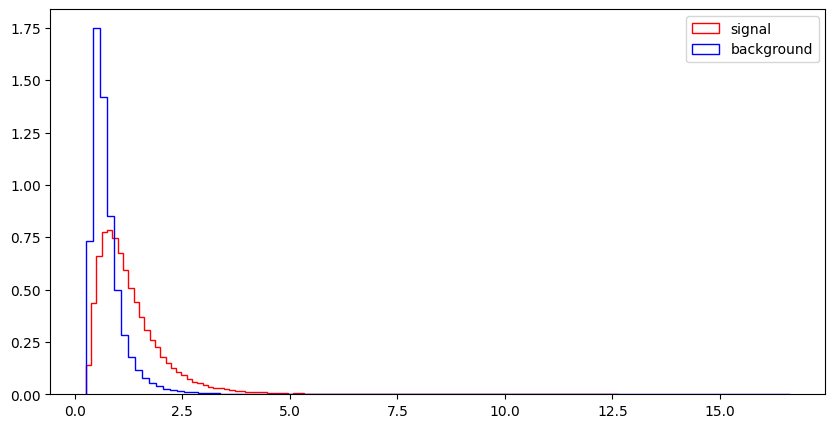

l_1_eta


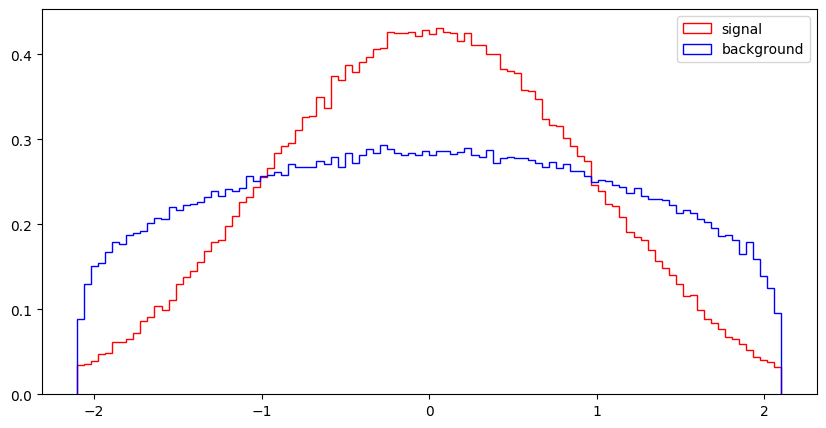

l_1_phi


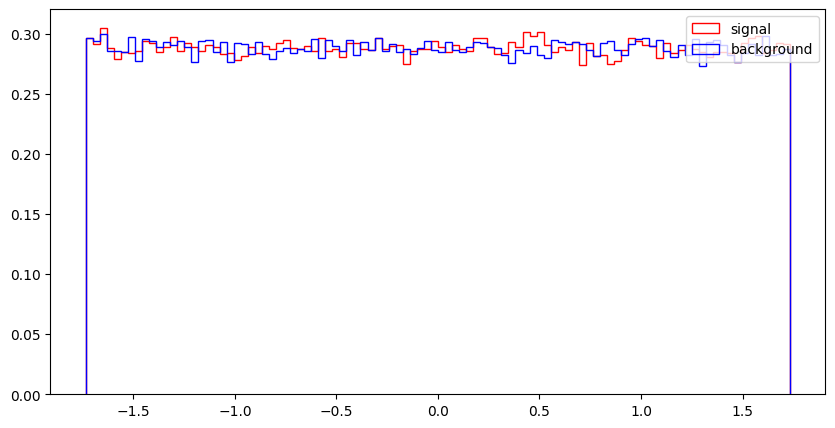

l_2_pT


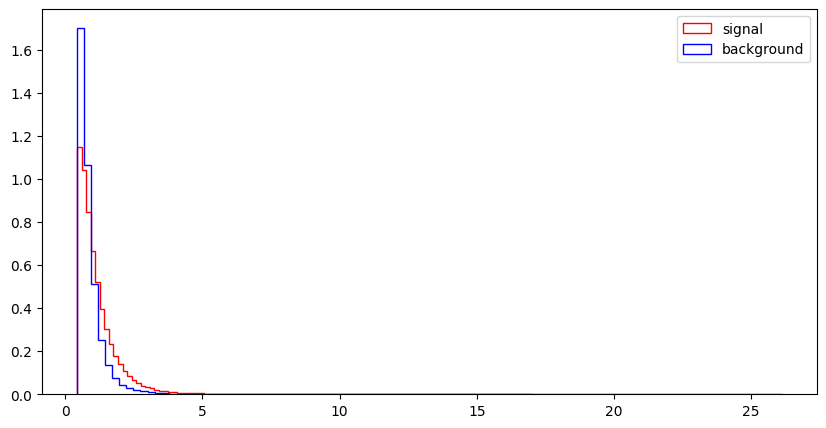

l_2_eta


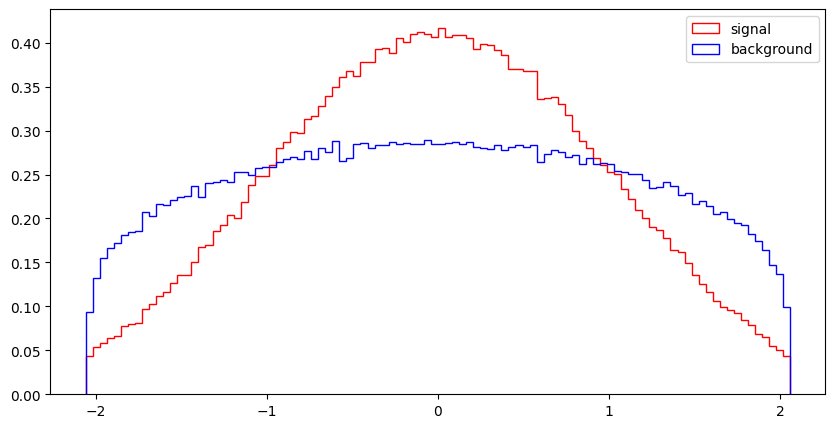

l_2_phi


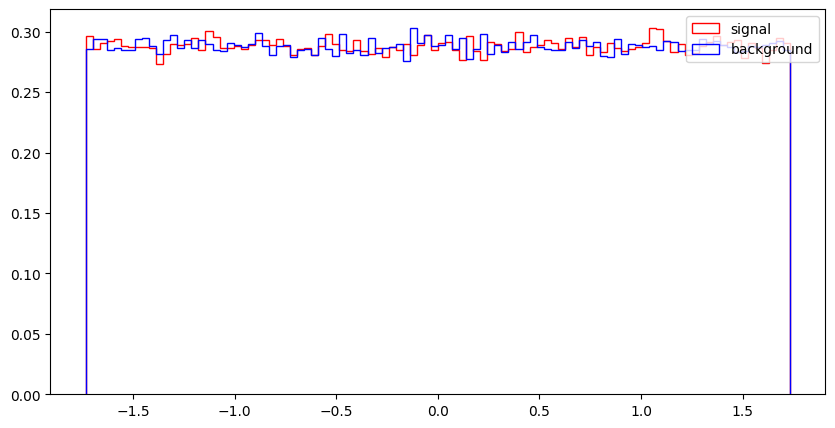

MET


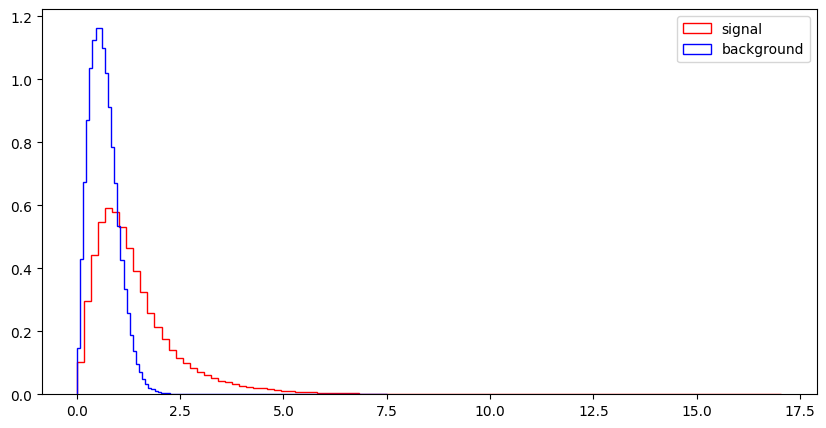

MET_phi


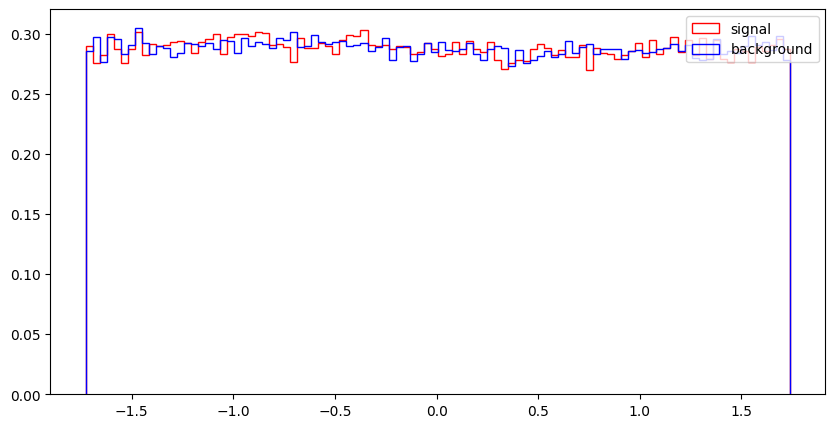

MET_rel


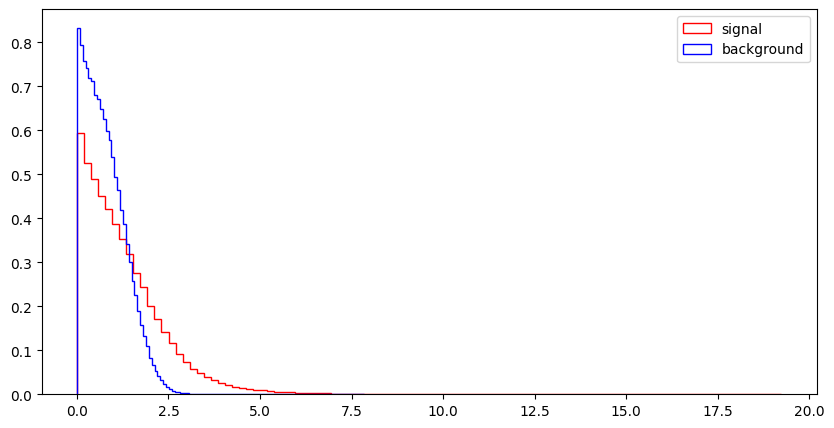

axial_MET


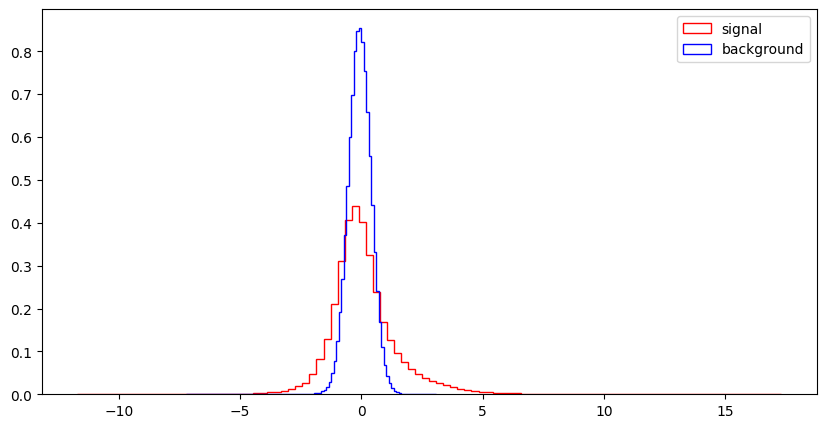

M_R


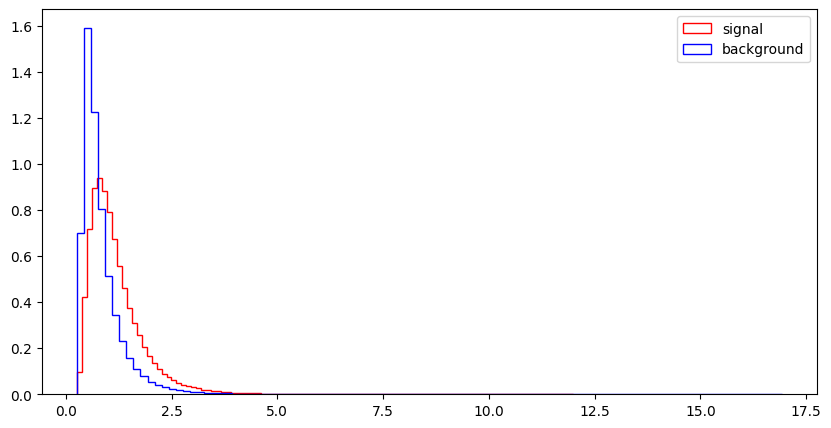

M_TR_2


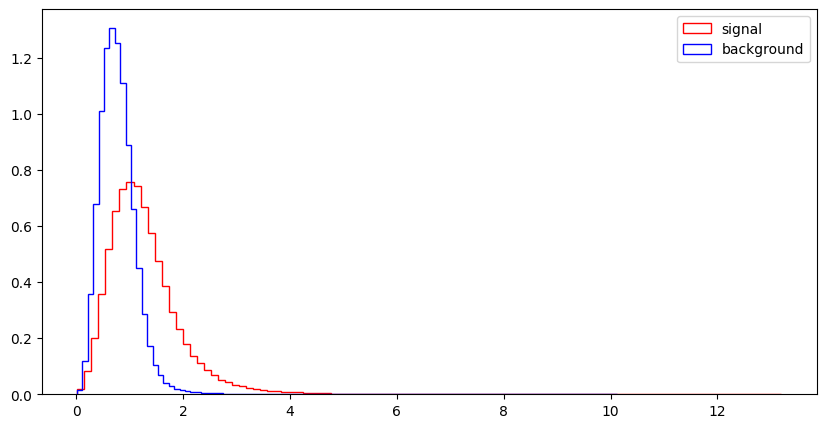

R


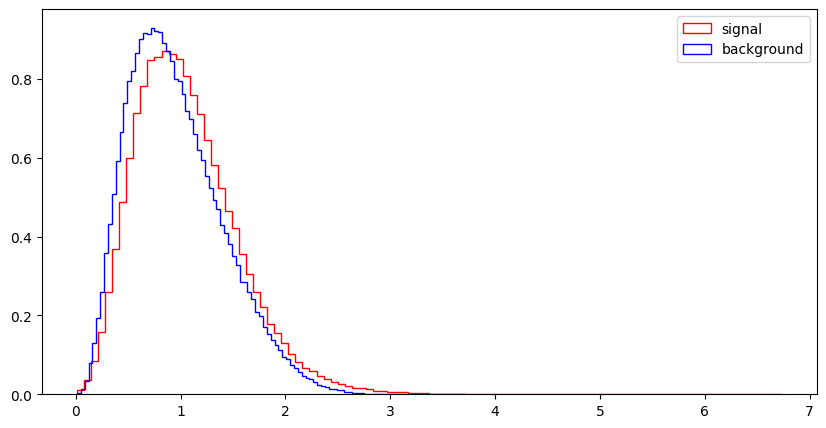

MT2


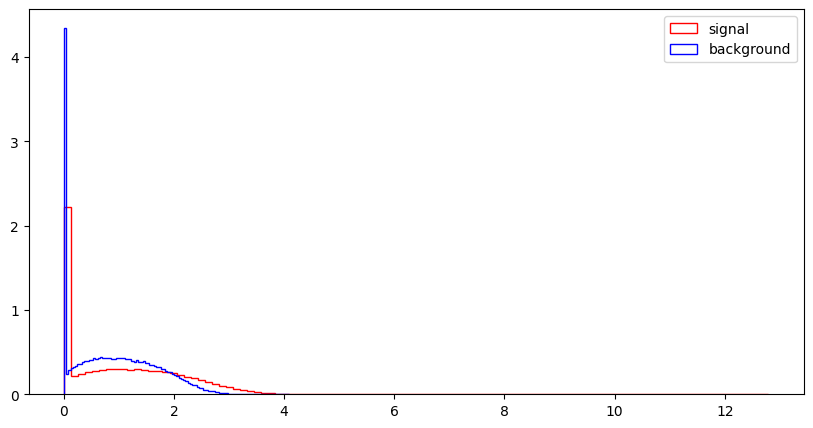

S_R


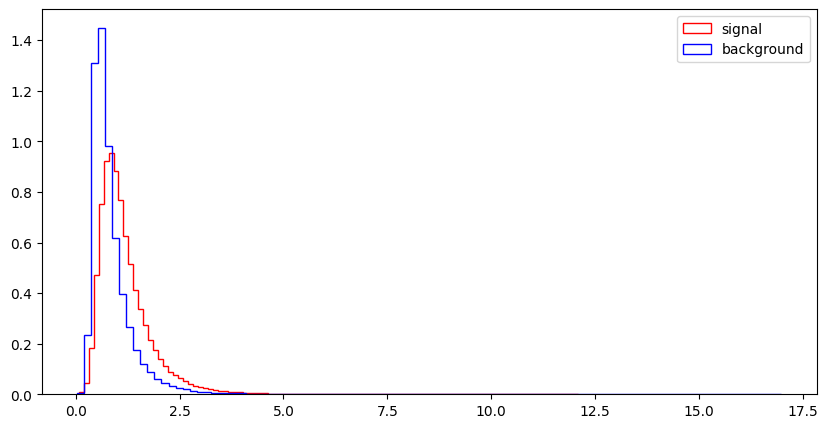

M_Delta_R


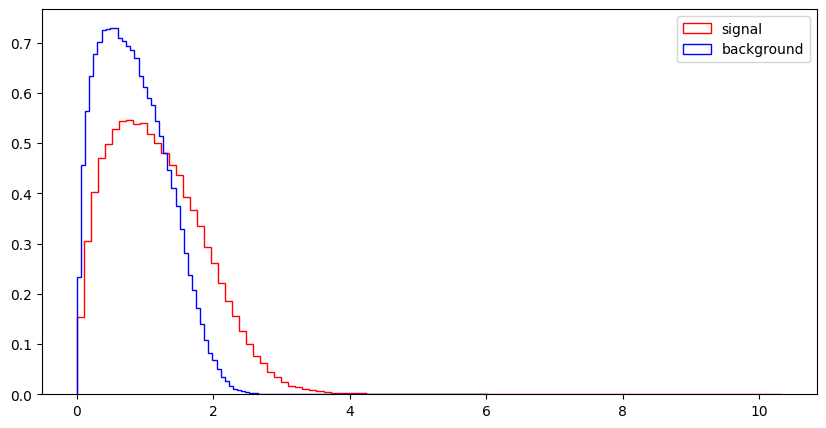

dPhi_r_b


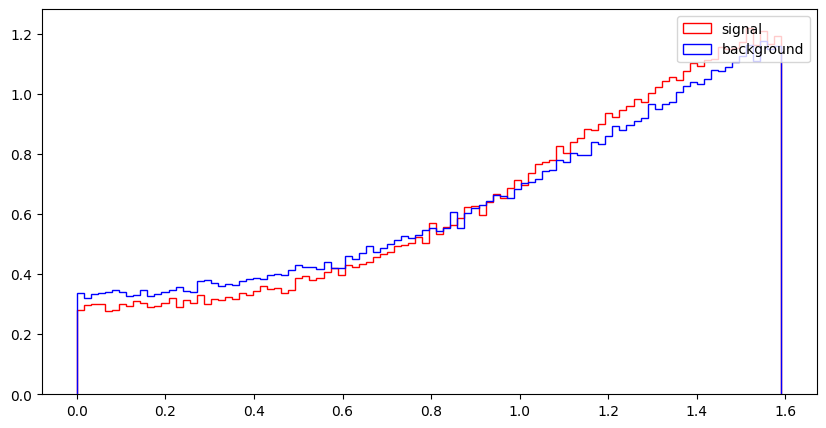

cos_theta_r1


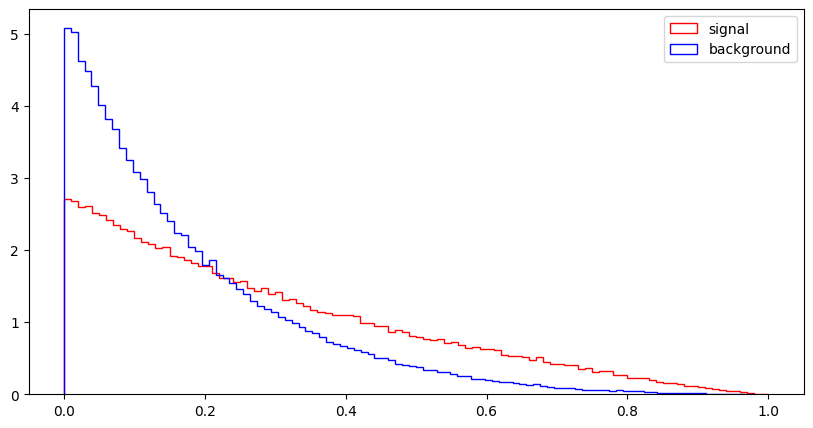

In [35]:
import numpy as np
for var in VarNames[1:]:
    print (var)
    plt.figure(figsize=(10,5))
    plt.hist(np.array(df_sig[var]),bins=100,histtype="step", color="red",label="signal",density=1, stacked=True)
    plt.hist(np.array(df_bkg[var]),bins=100,histtype="step", color="blue", label="background",density=1, stacked=True)
    plt.legend(loc='upper right')
    plt.show()

## Exercise 3: Make nice figures

Now use `matplotlib` to reproduce as closely as you can figures 5 and 6 from the paper. This exercise is intended to get you to familiarize yourself with making nicely formatted `matplotlib` figures with multiple plots. Note that the plots in the paper are actually wrong!

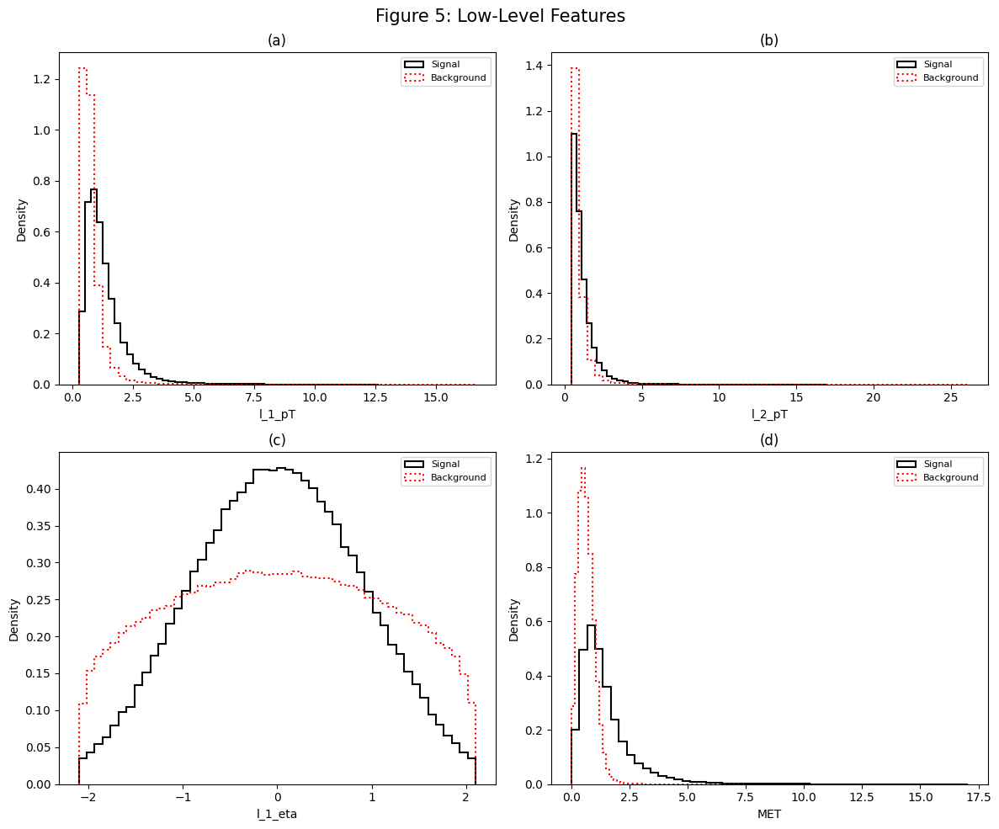

In [37]:
import matplotlib.pyplot as plt
import numpy as np

# Variables available in the SUSY dataset
variables = ["l_1_pT", "l_2_pT", "l_1_eta", "MET"]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, var in enumerate(variables):
    ax = axes[i]

    ax.hist(df_sig[var], bins=50, density=True,
            histtype="step", color="black",
            linewidth=1.5, label="Signal")

    ax.hist(df_bkg[var], bins=50, density=True,
            histtype="step", color="red",
            linestyle="dotted", linewidth=1.5,
            label="Background")

    ax.set_xlabel(var)
    ax.set_ylabel("Density")
    ax.set_title(f"({chr(97+i)})")
    ax.legend(fontsize=8)

plt.suptitle("Figure 5: Low-Level Features", fontsize=15)
plt.tight_layout()
plt.show()

In [41]:
HighNames = VarNames[9:]

print(HighNames)

['MET_rel', 'axial_MET', 'M_R', 'M_TR_2', 'R', 'MT2', 'S_R', 'M_Delta_R', 'dPhi_r_b', 'cos_theta_r1']


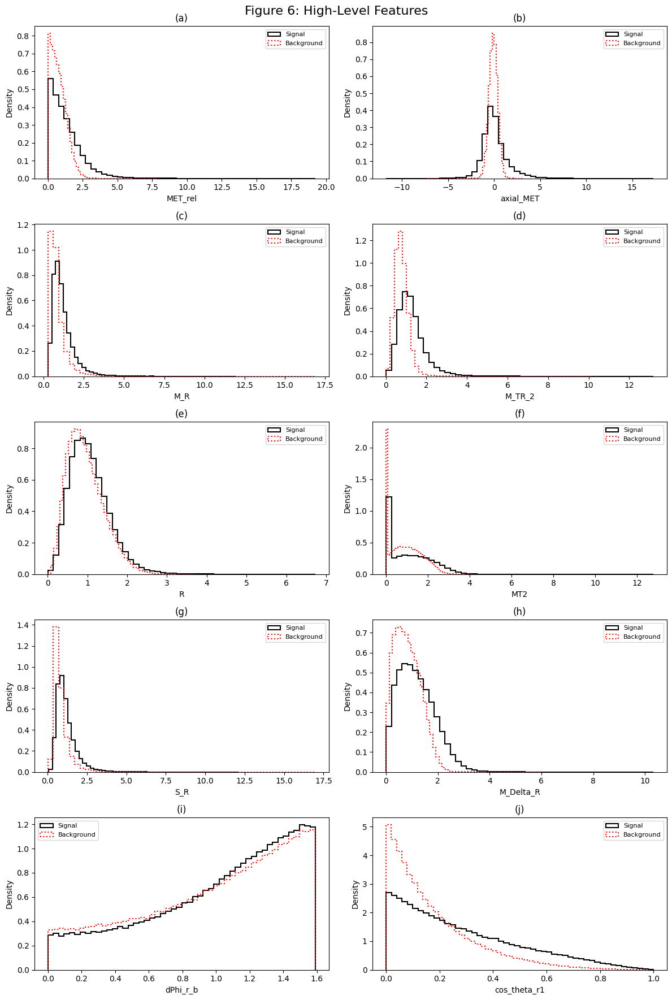

In [42]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(5, 2, figsize=(12, 18))
axes = axes.flatten()

for i, var in enumerate(HighNames):
    ax = axes[i]

    ax.hist(df_sig[var], bins=50, density=True,
            histtype="step", color="black",
            linewidth=1.5, label="Signal")

    ax.hist(df_bkg[var], bins=50, density=True,
            histtype="step", color="red",
            linestyle="dotted", linewidth=1.5,
            label="Background")

    ax.set_xlabel(var)
    ax.set_ylabel("Density")
    ax.set_title(f"({chr(97+i)})")
    ax.legend(fontsize=8)

plt.suptitle("Figure 6: High-Level Features", fontsize=16)
plt.tight_layout()
plt.show()

## Exercise 4: Correlation

### Exercise 4.1

#### Part a
Write a function that creates pair plots and use it to compare variables in the SUSY sample, separately for low and high-level features. Refer to Lecture 13 for details. Do not use `seaborn`.

#### Part b
Making these plots can be slow because creating each plot initiates a full loop over the data. Make at least one modification to your function in part a to speed it up. Can you propose a different method of creating histograms that would speed up making such pair plots?

#### Part c
Which observables appear to be best for separating signal from background?

In [44]:
import numpy as np
import matplotlib.pyplot as plt

def pair_plot(data, variables, sample_size=2000):
    # Take a smaller sample to make plotting faster
    sample = data.sample(
        n=min(sample_size, len(data)),
        random_state=72
    )

    n = len(variables)
    fig, axes = plt.subplots(n, n, figsize=(3*n, 3*n))

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]

            if i == j:
                # Histogram on the diagonal
                for label, color in [(1, "red"), (0, "blue")]:
                    subset = sample[sample["signal"] == label]
                    ax.hist(subset[variables[i]], bins=30,
                            density=True, histtype="step",
                            color=color)
            else:
                # Scatter plot comparing two variables
                for label, color in [(1, "red"), (0, "blue")]:
                    subset = sample[sample["signal"] == label]
                    ax.scatter(
                        subset[variables[j]],
                        subset[variables[i]],
                        s=2, alpha=0.3, color=color
                    )

            if i == n - 1:
                ax.set_xlabel(variables[j], fontsize=8)

            if j == 0:
                ax.set_ylabel(variables[i], fontsize=8)

            ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

['l_1_pT', 'l_1_eta', 'l_1_phi', 'l_2_pT', 'l_2_eta', 'l_2_phi', 'MET', 'MET_phi']


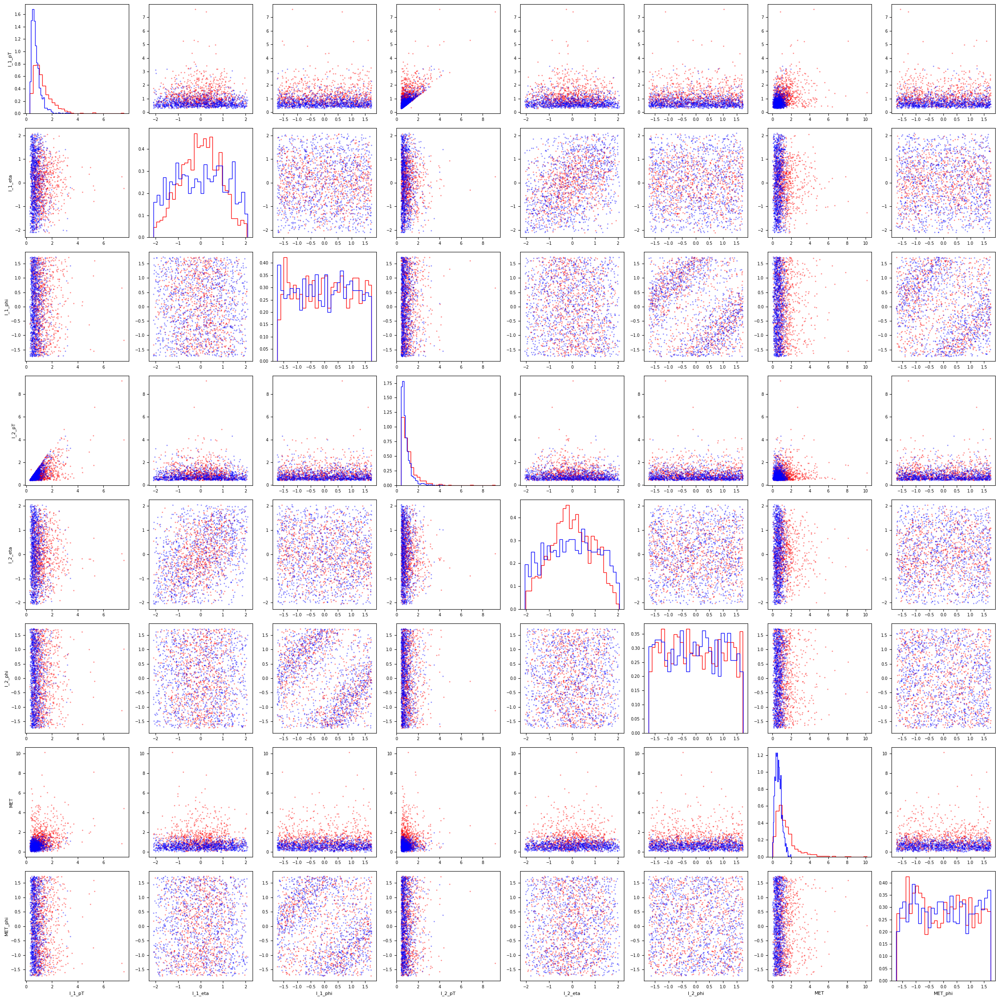

In [45]:
print(RawNames)

pair_plot(df, RawNames)

['axial_MET', 'R', 'S_R', 'MET_rel', 'MT2', 'M_TR_2', 'dPhi_r_b', 'M_Delta_R', 'M_R', 'cos_theta_r1']


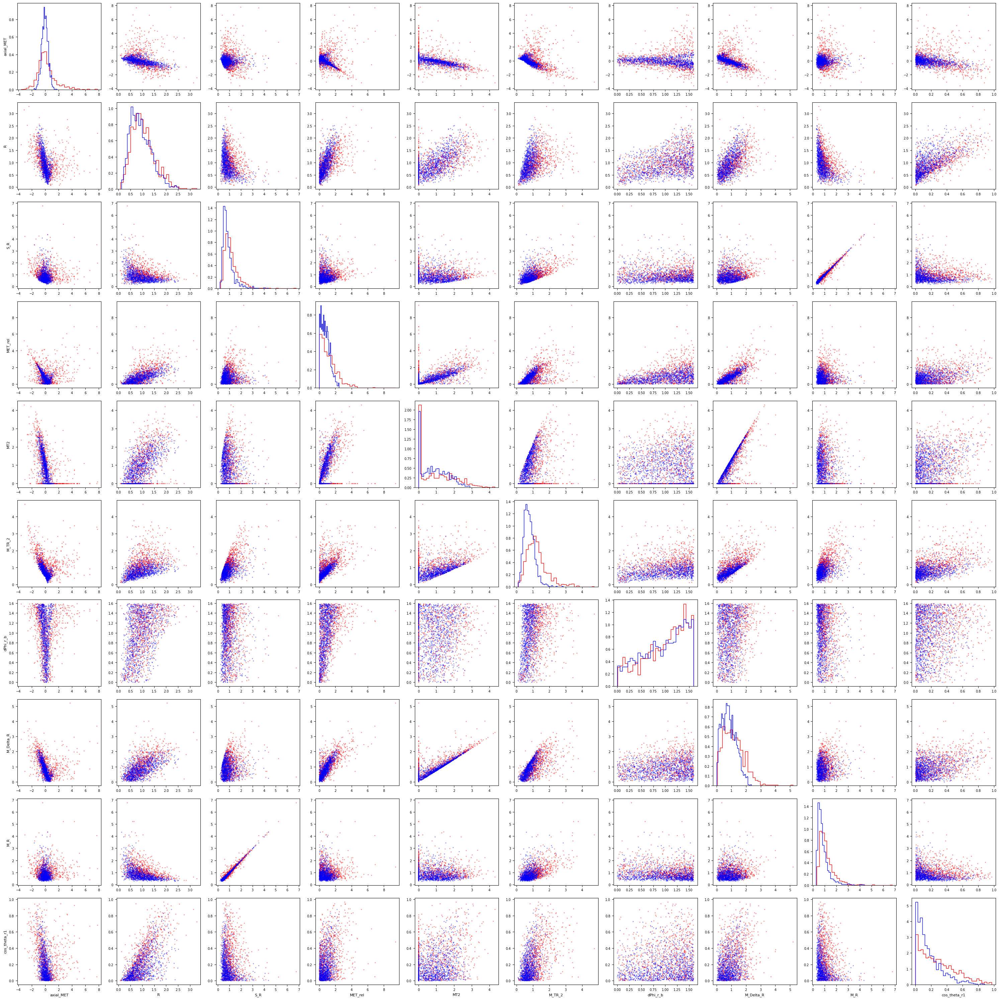

In [46]:
print(FeatureNames)

pair_plot(df, FeatureNames)

In [48]:
def pair_plot_fast(data, variables, sample_size=2000):
    sample = data.sample(
        n=min(sample_size, len(data)),
        random_state=72
    )

    sig = sample[sample["signal"] == 1]
    bkg = sample[sample["signal"] == 0]

    n = len(variables)
    fig, axes = plt.subplots(n, n, figsize=(3*n, 3*n))

    for i in range(n):
        for j in range(n):
            ax = axes[i, j]

            if i == j:
                ax.hist(sig[variables[i]], bins=30,
                        density=True, histtype="step",
                        color="red")

                ax.hist(bkg[variables[i]], bins=30,
                        density=True, histtype="step",
                        color="blue")
            else:
                ax.scatter(sig[variables[j]], sig[variables[i]],
                           s=2, alpha=0.3, color="red")

                ax.scatter(bkg[variables[j]], bkg[variables[i]],
                           s=2, alpha=0.3, color="blue")

            if i == n - 1:
                ax.set_xlabel(variables[j], fontsize=8)

            if j == 0:
                ax.set_ylabel(variables[i], fontsize=8)

            ax.tick_params(labelsize=7)

    plt.tight_layout()
    plt.show()

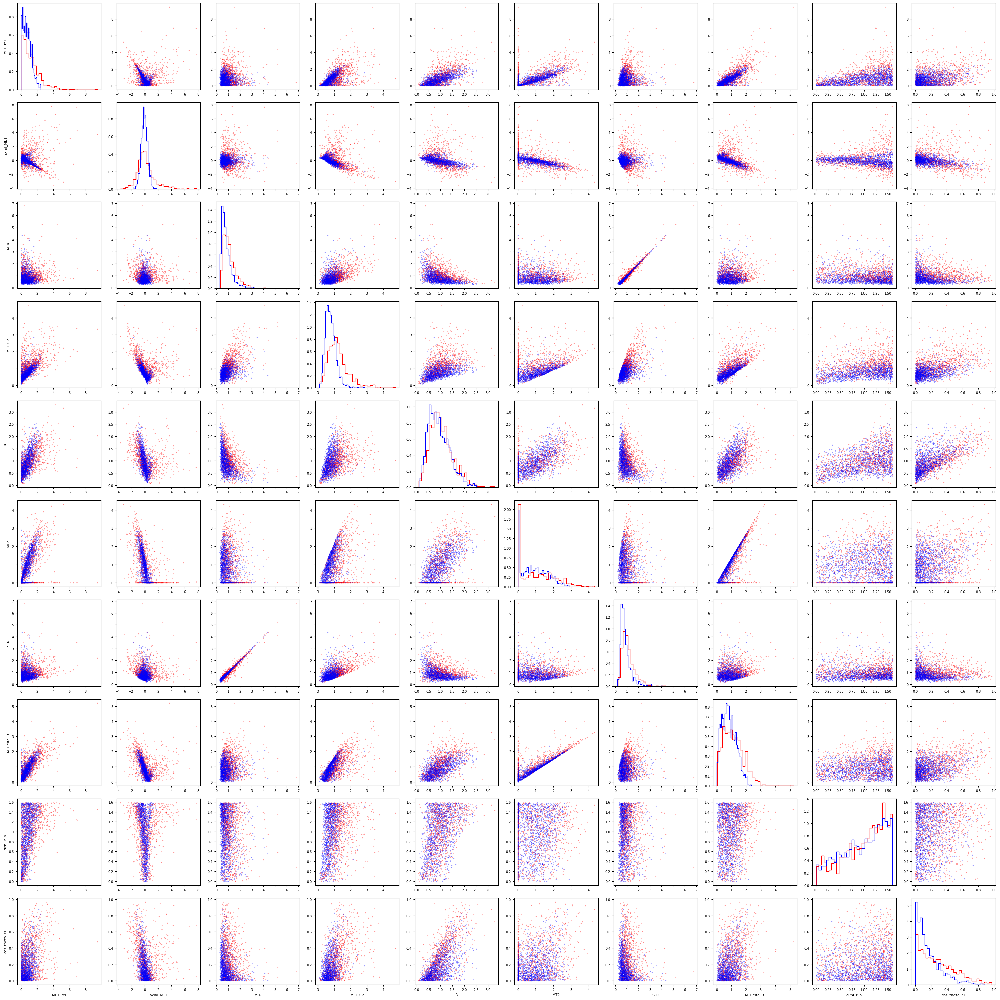

In [50]:
HighNames = VarNames[9:]

pair_plot_fast(df, HighNames)

In [52]:
import pandas as pd
import numpy as np

results = []

for var in VarNames[1:]:
    mean_sig = df_sig[var].mean()
    mean_bkg = df_bkg[var].mean()

    std_sig = df_sig[var].std()
    std_bkg = df_bkg[var].std()

    separation = abs(mean_sig - mean_bkg) / np.sqrt(
        (std_sig**2 + std_bkg**2) / 2
    )

    results.append([var, separation])

separation_df = pd.DataFrame(
    results, columns=["Variable", "Separation"]
)

separation_df = separation_df.sort_values(
    "Separation", ascending=False
)

print(separation_df.to_string(index=False))

    Variable  Separation
         MET    0.948809
      M_TR_2    0.920642
      l_1_pT    0.833484
     MET_rel    0.577386
   M_Delta_R    0.564387
         M_R    0.559219
cos_theta_r1    0.548681
         S_R    0.540526
      l_2_pT    0.397248
           R    0.219557
         MT2    0.158675
   axial_MET    0.154042
    dPhi_r_b    0.065939
     l_2_eta    0.002886
     MET_phi    0.001184
     l_1_phi    0.000869
     l_1_eta    0.000862
     l_2_phi    0.000681


### Exercise 4.2

#### Part a
Install [tabulate](https://github.com/astanin/python-tabulate). 

#### Part b
Use numpy to compute the [covariance matrix](https://numpy.org/doc/stable/reference/generated/numpy.cov.html) and [correlation matrix](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) between all observables, and separately between low and high-level features.

#### Part c
Use tabulate to create a well formatted table of the covariance and correlation matrices, with nice headings and appropriate significant figures. Embed the table into this notebook.

#### Part d
Write a function that takes a dataset and appropriate arguments and performs steps b and c.  

In [53]:
%pip install tabulate

Note: you may need to restart the kernel to use updated packages.


In [54]:
from tabulate import tabulate

print("Tabulate installed successfully!")

Tabulate installed successfully!


In [55]:
import numpy as np

# Define feature groups
RawNames = VarNames[1:9]
HighNames = VarNames[9:]
AllNames = VarNames[1:]

# Calculate covariance and correlation matrices
for name, variables in [
    ("All Observables", AllNames),
    ("Low-Level Features", RawNames),
    ("High-Level Features", HighNames)
]:
    X = df[variables].to_numpy()

    covariance = np.cov(X, rowvar=False)
    correlation = np.corrcoef(X, rowvar=False)

    print(f"\n{name}")
    print("Covariance matrix shape:", covariance.shape)
    print("Correlation matrix shape:", correlation.shape)


All Observables
Covariance matrix shape: (18, 18)
Correlation matrix shape: (18, 18)

Low-Level Features
Covariance matrix shape: (8, 8)
Correlation matrix shape: (8, 8)

High-Level Features
Covariance matrix shape: (10, 10)
Correlation matrix shape: (10, 10)


In [56]:
from tabulate import tabulate

# Example: Low-level correlation matrix
X = df[RawNames].to_numpy()

corr = np.corrcoef(X, rowvar=False)

print(tabulate(
    corr,
    headers=RawNames,
    showindex=RawNames,
    tablefmt="grid",
    floatfmt=".3f"
))

+---------+----------+-----------+-----------+----------+-----------+-----------+--------+-----------+
|         |   l_1_pT |   l_1_eta |   l_1_phi |   l_2_pT |   l_2_eta |   l_2_phi |    MET |   MET_phi |
+=========+==========+===========+===========+==========+===========+===========+========+===========+
| l_1_pT  |    1.000 |    -0.001 |     0.000 |    0.684 |    -0.001 |     0.001 |  0.383 |    -0.001 |
+---------+----------+-----------+-----------+----------+-----------+-----------+--------+-----------+
| l_1_eta |   -0.001 |     1.000 |    -0.001 |   -0.000 |     0.406 |    -0.001 | -0.002 |    -0.001 |
+---------+----------+-----------+-----------+----------+-----------+-----------+--------+-----------+
| l_1_phi |    0.000 |    -0.001 |     1.000 |    0.002 |     0.000 |    -0.266 |  0.001 |    -0.184 |
+---------+----------+-----------+-----------+----------+-----------+-----------+--------+-----------+
| l_2_pT  |    0.684 |    -0.000 |     0.002 |    1.000 |    -0.001 |    

In [57]:
def matrix_tables(data, variables, title):
    X = data[variables].to_numpy()

    cov = np.cov(X, rowvar=False)
    corr = np.corrcoef(X, rowvar=False)

    print(f"\n{title} - Covariance Matrix")
    print(tabulate(
        cov,
        headers=variables,
        showindex=variables,
        tablefmt="grid",
        floatfmt=".3f"
    ))

    print(f"\n{title} - Correlation Matrix")
    print(tabulate(
        corr,
        headers=variables,
        showindex=variables,
        tablefmt="grid",
        floatfmt=".3f"
    ))

    return cov, corr

In [58]:
all_cov, all_corr = matrix_tables(
    df, AllNames, "All Observables"
)

raw_cov, raw_corr = matrix_tables(
    df, RawNames, "Low-Level Features"
)

high_cov, high_corr = matrix_tables(
    df, HighNames, "High-Level Features"
)


All Observables - Covariance Matrix
+--------------+----------+-----------+-----------+----------+-----------+-----------+--------+-----------+-----------+-------------+--------+----------+--------+--------+--------+-------------+------------+----------------+
|              |   l_1_pT |   l_1_eta |   l_1_phi |   l_2_pT |   l_2_eta |   l_2_phi |    MET |   MET_phi |   MET_rel |   axial_MET |    M_R |   M_TR_2 |      R |    MT2 |    S_R |   M_Delta_R |   dPhi_r_b |   cos_theta_r1 |
+==============+==========+===========+===========+==========+===========+===========+========+===========+===========+=============+========+==========+========+========+========+=============+============+================+
| l_1_pT       |    0.467 |    -0.000 |     0.000 |    0.305 |    -0.000 |     0.001 |  0.228 |    -0.001 |     0.098 |      -0.010 |  0.364 |    0.287 | -0.060 | -0.012 |  0.343 |       0.098 |     -0.047 |          0.022 |
+--------------+----------+-----------+-----------+----------+-

Hint: Example code for embedding a `tabulate` table into a notebook:

In [59]:
from IPython.display import HTML, display
import tabulate
table = [["A",1,2],
        ["C",3,4],
        ["D",5,6]]
display(HTML(tabulate.tabulate(table, tablefmt='html', headers=["X","Y","Z"])))

X,Y,Z
A,1,2
C,3,4
D,5,6


In [ ]:
##The covariance and correlation matrices show the relationships among the SUSY observables. Some variables have strong positive correlations, suggesting that they may contain overlapping information. For example, MT2 and M_Delta_R have a correlation of approximately 0.809, indicating a strong positive linear relationship. Other variables have correlations close to zero, suggesting little linear association. Understanding these relationships is important when selecting variables for classification because highly correlated variables may provide redundant information.

## Exercise 5: Selection

### Exercise 5.1

Part a
By looking at the signal/background distributions for each observable (e.g. $x$) determine which selection criteria would be optimal: 

1. $x > x_c$
2. $x < x_c$
3. $|x - \mu| > x_c$
4. $|x - \mu| < x_c$

where $x_c$ is value to be determined below.

### Exercise 5.2

Plot the True Positive Rate (TPR) (aka signal efficiency $\epsilon_S(x_c)$) and False Positive Rate (FPR) (aka background efficiency $\epsilon_B(x_c)$) as function of $x_c$ for applying the strategy in Exercise 5.1 to each observable. 

### Exercise 5.3
Assume 4 different scenarios corresponding to different numbers of signal and background events expected in data:

1. Expect $N_S=10$, $N_B=100$.
1. Expect $N_S=100$, $N_B=1000$.
1. Expect $N_S=1000$, $N_B=10000$.
1. Expect $N_S=10000$, $N_B=100000$.

Plot the significance ($\sigma_{S'}$) for each observable as function of $x_c$ for each scenario, where 

$\sigma_{S'}= \frac{N'_S}{\sqrt{N'_S+N'_B}}$

and $N'_{S,B} = \epsilon_{S,B}(x_c) * N_{S,B}$.

In [60]:
#5.1
variables = ["MET", "M_TR_2", "l_1_pT"]

for var in variables:
    print(f"\nVariable: {var}")
    print("Signal mean:", round(df_sig[var].mean(), 4))
    print("Background mean:", round(df_bkg[var].mean(), 4))


Variable: MET
Signal mean: 1.4184
Background mean: 0.6479

Variable: M_TR_2
Signal mean: 1.2689
Background mean: 0.7721

Variable: l_1_pT
Signal mean: 1.2911
Background mean: 0.7544


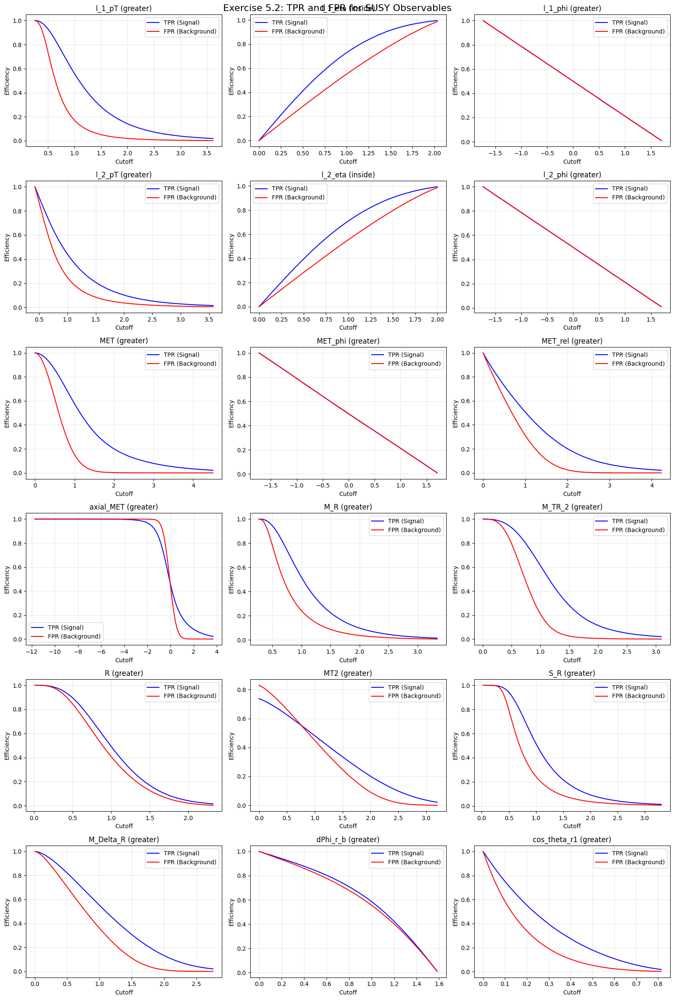

In [66]:
#5.2
import numpy as np
import matplotlib.pyplot as plt

# All 18 observables
variables = VarNames[1:]

# Selection strategies based on distribution shapes
# "greater": x > xc
# "less": x < xc
# "inside": |x - mu| < xc
# "outside": |x - mu| > xc

selection_rules = {
    "l_1_pT": "greater",
    "l_1_eta": "inside",
    "l_1_phi": "greater",
    "l_2_pT": "greater",
    "l_2_eta": "inside",
    "l_2_phi": "greater",
    "MET": "greater",
    "MET_phi": "greater",
    "MET_rel": "greater",
    "axial_MET": "greater",
    "M_R": "greater",
    "M_TR_2": "greater",
    "R": "greater",
    "MT2": "greater",
    "S_R": "greater",
    "M_Delta_R": "greater",
    "dPhi_r_b": "greater",
    "cos_theta_r1": "greater"
}

# Function to apply selection criteria
def apply_selection(values, cutoff, rule, mu=0):
    if rule == "greater":
        return values > cutoff
    elif rule == "less":
        return values < cutoff
    elif rule == "inside":
        return np.abs(values - mu) < cutoff
    elif rule == "outside":
        return np.abs(values - mu) > cutoff

# Create 18 plots
fig, axes = plt.subplots(6, 3, figsize=(16, 24))
axes = axes.flatten()

for i, var in enumerate(variables):
    ax = axes[i]
    rule = selection_rules[var]

    signal_values = df_sig[var].to_numpy()
    background_values = df_bkg[var].to_numpy()

    mu = df[var].mean()

    # Determine cutoff range
    if rule in ["inside", "outside"]:
        all_values = np.abs(df[var].to_numpy() - mu)
    else:
        all_values = df[var].to_numpy()

    cutoffs = np.linspace(
        np.min(all_values),
        np.quantile(all_values, 0.99),
        100
    )

    tpr = []
    fpr = []

    for cutoff in cutoffs:
        signal_selected = apply_selection(
            signal_values, cutoff, rule, mu
        )

        background_selected = apply_selection(
            background_values, cutoff, rule, mu
        )

        tpr.append(np.mean(signal_selected))
        fpr.append(np.mean(background_selected))

    ax.plot(cutoffs, tpr, color="blue", label="TPR (Signal)")
    ax.plot(cutoffs, fpr, color="red", label="FPR (Background)")

    ax.set_title(f"{var} ({rule})")
    ax.set_xlabel("Cutoff")
    ax.set_ylabel("Efficiency")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Exercise 5.2: TPR and FPR for SUSY Observables",
             fontsize=16)

plt.tight_layout()
plt.show()

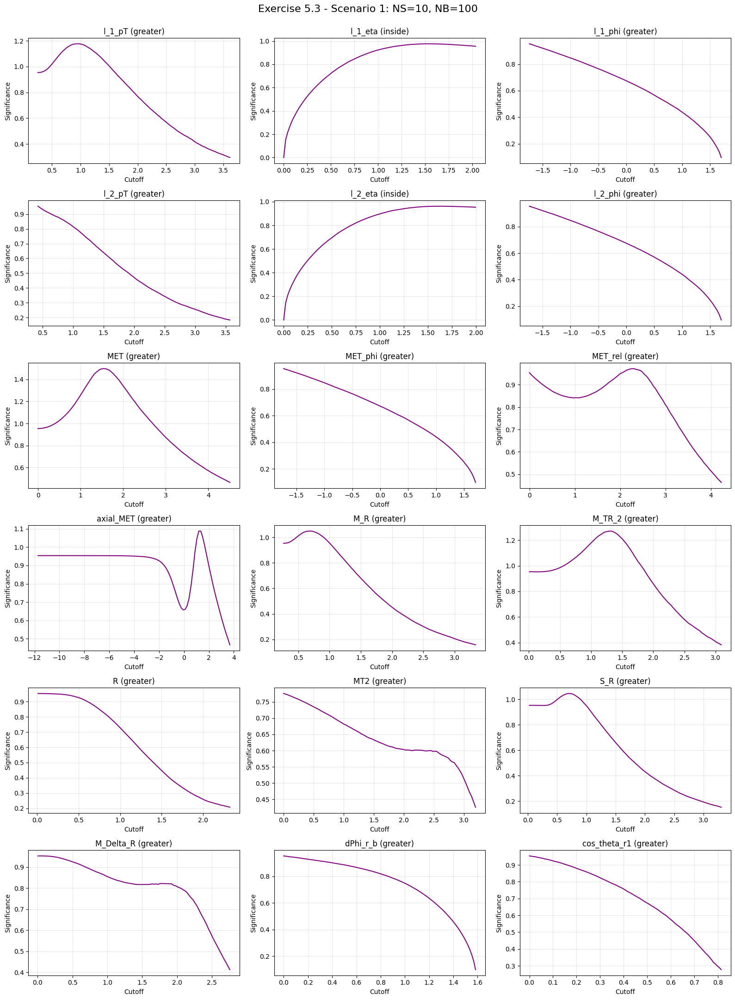

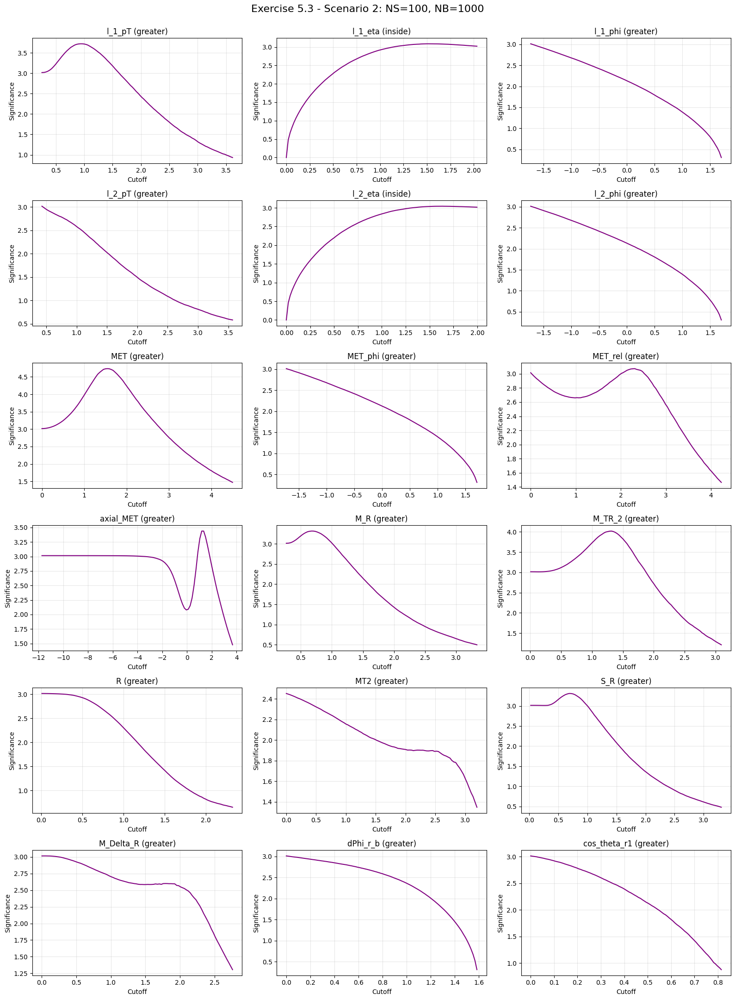

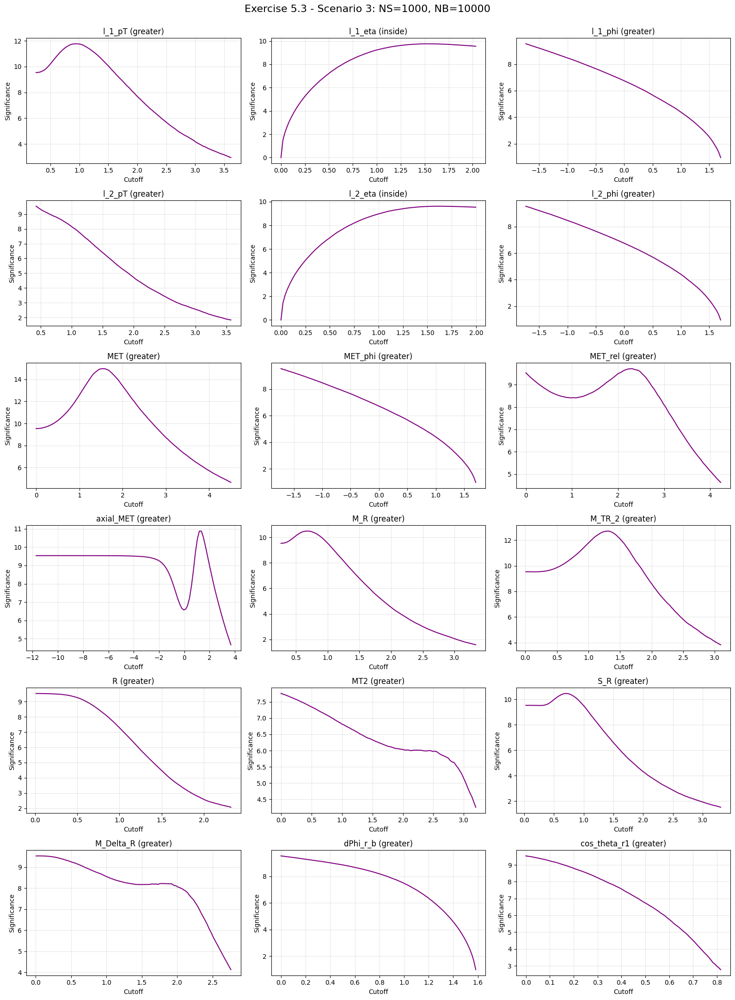

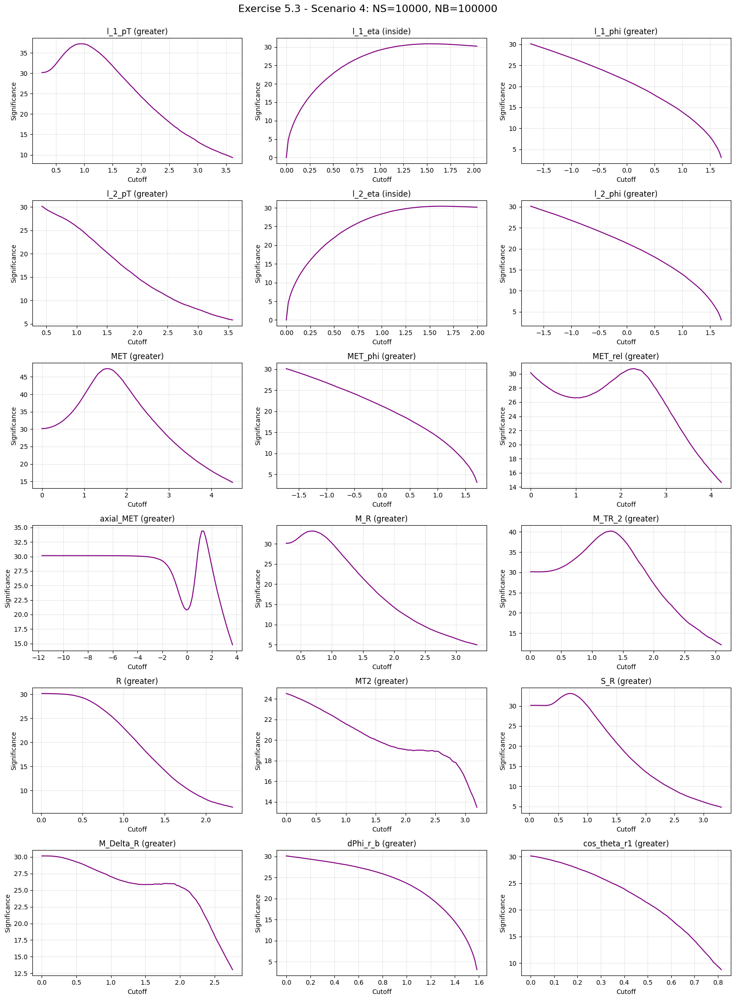

In [67]:
import numpy as np
import matplotlib.pyplot as plt

# Four scenarios from Exercise 5.3
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

# All 18 observables
variables = VarNames[1:]

# Store results for later use
significance_results = {}

for scenario_num, (NS, NB) in enumerate(scenarios, start=1):

    fig, axes = plt.subplots(6, 3, figsize=(16, 22))
    axes = axes.flatten()

    for i, var in enumerate(variables):
        ax = axes[i]

        rule = selection_rules[var]
        mu = df[var].mean()

        signal_values = df_sig[var].to_numpy()
        background_values = df_bkg[var].to_numpy()

        # Determine cutoff range
        if rule in ["inside", "outside"]:
            all_values = np.abs(df[var].to_numpy() - mu)
        else:
            all_values = df[var].to_numpy()

        cutoffs = np.linspace(
            np.min(all_values),
            np.quantile(all_values, 0.99),
            100
        )

        tpr = []
        fpr = []

        # Calculate signal and background efficiencies
        for cutoff in cutoffs:

            signal_selected = apply_selection(
                signal_values, cutoff, rule, mu
            )

            background_selected = apply_selection(
                background_values, cutoff, rule, mu
            )

            tpr.append(np.mean(signal_selected))
            fpr.append(np.mean(background_selected))

        tpr = np.array(tpr)
        fpr = np.array(fpr)

        # Expected events after selection
        S = tpr * NS
        B = fpr * NB

        # Calculate significance
        significance = np.divide(
            S,
            np.sqrt(S + B),
            out=np.zeros_like(S),
            where=(S + B) > 0
        )

        # Store results
        significance_results[(scenario_num, var)] = {
            "cutoffs": cutoffs,
            "significance": significance
        }

        # Plot significance
        ax.plot(cutoffs, significance, color="purple")

        ax.set_title(f"{var} ({rule})")
        ax.set_xlabel("Cutoff")
        ax.set_ylabel("Significance")
        ax.grid(alpha=0.3)

    plt.suptitle(
        f"Exercise 5.3 - Scenario {scenario_num}: "
        f"NS={NS}, NB={NB}",
        fontsize=16
    )

    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()

In [69]:
import pandas as pd

best_results = []

for scenario_num, (NS, NB) in enumerate(scenarios, start=1):
    for var in variables:

        result = significance_results[(scenario_num, var)]

        cutoffs = result["cutoffs"]
        significance = result["significance"]

        best_index = np.argmax(significance)

        best_results.append({
            "Scenario": scenario_num,
            "Variable": var,
            "Best Cutoff": cutoffs[best_index],
            "Max Significance": significance[best_index]
        })

best_df = pd.DataFrame(best_results)

display(best_df.round(4))

,Scenario,Variable,Best Cutoff,Max Significance
0,1,l_1_pT,0.9339,1.1764
1,1,l_1_eta,1.4992,0.9761
2,1,l_1_phi,-1.7348,0.9535
3,1,l_2_pT,0.4286,0.9535
4,1,l_2_eta,1.6333,0.9623
...,...,...,...,...
67,4,MT2,0.0000,24.5250
68,4,S_R,0.6890,33.1024
69,4,M_Delta_R,0.0601,30.1556
70,4,dPhi_r_b,0.0000,30.1510


In [70]:
best_overall = best_df.loc[
    best_df.groupby("Scenario")["Max Significance"].idxmax()
]

display(best_overall.round(4))

,Scenario,Variable,Best Cutoff,Max Significance
6,1,MET,1.5471,1.4979
24,2,MET,1.5471,4.7366
42,3,MET,1.5471,14.9785
60,4,MET,1.5471,47.3663


In [ ]:
#I calculated the statistical significance for all 18 observables under four different scenarios. Based on the selection criteria and cutoffs tested, MET produced the highest significance in every scenario, with an optimal cutoff of approximately 1.5471. The maximum significance values were 1.4979, 4.7366, 14.9785, and 47.3663 for Scenarios 1 through 4, respectively. As the expected number of signal and background events increased, the statistical significance also increased. However, the optimal cutoff remained the same because the signal-to-background ratio was constant across all four scenarios. Overall, MET was the most effective observable for maximizing statistical significance among the tested selections.

## Exercise 6: Cut Flow


### Exercise 6.1

For each above scenario, choose a subset (minimum 3) of observables to use for selections, and values of $x_c$ based on your significance plots (Exercise 5.3). 

### Exercise 6.2
Create a "cut-flow" table for each scenario where you successively make the selections on each observable and tabulate $\epsilon_S$, $\epsilon_B$, $N'_S$, $N'_B$, and $\sigma_{S'}$.

### Exercise 6.3
In Exercise 5.3 you computed the significance for each observable assuming to make no other selections on any other observable. If the variables are correlated, then this assumption can lead to non-optimal results when selecting on multiple variables. By looking at the correlation matrices and your answers to Exercise 4.2, identify where this effect could be most detrimental to the significance. Attempt to correct the issue by applying the selection in one observable and then optimizing (as in Exercise 5.3) for a second observable. What happens if you change the order of your selection (make selection on second and optimize on first)?




In [71]:
# Exercise 6.1: Choose three observables

selected_vars = ["MET", "M_TR_2", "l_1_pT"]

# Retrieve optimal cutoffs from Exercise 5.3
selected_cuts = best_df[
    (best_df["Scenario"] == 1) &
    (best_df["Variable"].isin(selected_vars))
][["Variable", "Best Cutoff", "Max Significance"]]

display(selected_cuts.round(4))

,Variable,Best Cutoff,Max Significance
0,l_1_pT,0.9339,1.1764
6,MET,1.5471,1.4979
11,M_TR_2,1.3174,1.2707


In [72]:
# Exercise 6.2: Cut-flow table

import numpy as np
import pandas as pd

# Selection criteria from Exercise 6.1
cuts = [
    ("MET", 1.5471),
    ("M_TR_2", 1.3174),
    ("l_1_pT", 0.9339)
]

# Four scenarios from Exercise 5.3
scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

# Original signal and background events in the dataset
total_signal = len(df_sig)
total_background = len(df_bkg)

# Store cut-flow results
cutflow_results = []

for scenario_num, (NS, NB) in enumerate(scenarios, start=1):

    # Start with all events selected
    selected = np.ones(len(df), dtype=bool)

    # Include initial events before any cuts
    steps = [("No cuts", None, None)] + [
        (var, cutoff, "greater") for var, cutoff in cuts
    ]

    for step_num, (var, cutoff, rule) in enumerate(steps):

        if step_num > 0:
            selected &= (df[var].to_numpy() > cutoff)

        # Count remaining signal and background events
        signal_remaining = np.sum(
            selected & (df["signal"].to_numpy() == 1)
        )

        background_remaining = np.sum(
            selected & (df["signal"].to_numpy() == 0)
        )

        # Calculate efficiencies
        eps_S = signal_remaining / total_signal
        eps_B = background_remaining / total_background

        # Expected events after cuts
        NS_prime = eps_S * NS
        NB_prime = eps_B * NB

        # Statistical significance
        if NS_prime + NB_prime > 0:
            significance = NS_prime / np.sqrt(
                NS_prime + NB_prime
            )
        else:
            significance = 0

        cutflow_results.append({
            "Scenario": scenario_num,
            "Cut": "No cuts" if step_num == 0
                   else f"{var} > {cutoff}",
            "Signal Efficiency": eps_S,
            "Background Efficiency": eps_B,
            "Selected Signal": NS_prime,
            "Selected Background": NB_prime,
            "Significance": significance
        })

# Create DataFrame
cutflow_df = pd.DataFrame(cutflow_results)

# Display results for all four scenarios
for scenario_num in range(1, 5):

    print(f"\nScenario {scenario_num}")

    display(
        cutflow_df[
            cutflow_df["Scenario"] == scenario_num
        ].round(4)
    )


Scenario 1


,Scenario,Cut,Signal Efficiency,Background Efficiency,Selected Signal,Selected Background,Significance
0,1,No cuts,1.0000,1.0000,10.0000,100.0000,0.9535
1,1,MET > 1.5471,0.3228,0.0142,3.2281,1.4168,1.4978
2,1,M_TR_2 > 1.3174,0.2330,0.0105,2.3301,1.0482,1.2677
3,1,l_1_pT > 0.9339,0.1909,0.0074,1.9093,0.7420,1.1726



Scenario 2


,Scenario,Cut,Signal Efficiency,Background Efficiency,Selected Signal,Selected Background,Significance
4,2,No cuts,1.0000,1.0000,100.0000,1000.0000,3.0151
5,2,MET > 1.5471,0.3228,0.0142,32.2812,14.1678,4.7365
6,2,M_TR_2 > 1.3174,0.2330,0.0105,23.3013,10.4818,4.0089
7,2,l_1_pT > 0.9339,0.1909,0.0074,19.0927,7.4200,3.7080



Scenario 3


,Scenario,Cut,Signal Efficiency,Background Efficiency,Selected Signal,Selected Background,Significance
8,3,No cuts,1.0000,1.0000,1000.0000,10000.0000,9.5346
9,3,MET > 1.5471,0.3228,0.0142,322.8118,141.6779,14.9783
10,3,M_TR_2 > 1.3174,0.2330,0.0105,233.0127,104.8180,12.6774
11,3,l_1_pT > 0.9339,0.1909,0.0074,190.9267,74.1999,11.7257



Scenario 4


,Scenario,Cut,Signal Efficiency,Background Efficiency,Selected Signal,Selected Background,Significance
12,4,No cuts,1.0000,1.0000,10000.0000,100000.0000,30.1511
13,4,MET > 1.5471,0.3228,0.0142,3228.1184,1416.7790,47.3654
14,4,M_TR_2 > 1.3174,0.2330,0.0105,2330.1272,1048.1801,40.0894
15,4,l_1_pT > 0.9339,0.1909,0.0074,1909.2674,741.9992,37.0800


In [ ]:
#The cut-flow analysis was performed using three observables: MET, M_TR_2, and l_1_pT. The first selection, MET > 1.5471, increased the statistical significance from 0.9535 to 1.4978 in Scenario 1. However, applying the additional cuts reduced the significance to 1.2677 and 1.1726, respectively. Although the additional cuts decreased background efficiency, they also removed signal events. Overall, the MET selection alone produced the highest statistical significance using the tested cutoff values. This suggests that combining individually optimized cuts does not necessarily improve the overall significance.

,MET,M_TR_2,l_1_pT
MET,1.0000,0.7197,0.3827
M_TR_2,0.7197,1.0000,0.7228
l_1_pT,0.3827,0.7228,1.0000


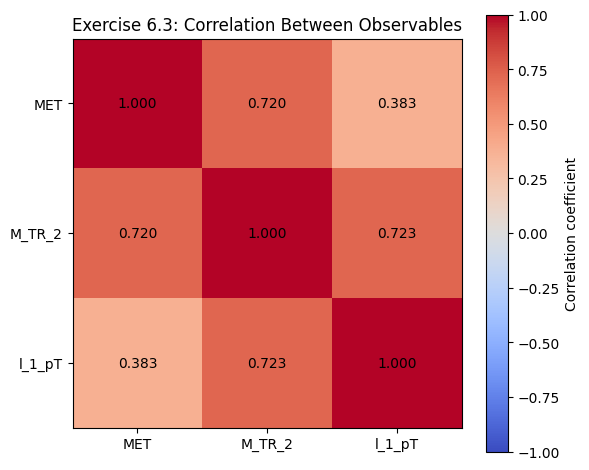

In [73]:
# Exercise 6.3: Correlation between selected observables

import matplotlib.pyplot as plt
import pandas as pd

selected_vars = ["MET", "M_TR_2", "l_1_pT"]

# Correlation matrix
corr_matrix = df[selected_vars].corr()

display(corr_matrix.round(4))

# Visualize correlation matrix
plt.figure(figsize=(6, 5))
plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation coefficient")

plt.xticks(range(3), selected_vars)
plt.yticks(range(3), selected_vars)

for i in range(3):
    for j in range(3):
        plt.text(
            j, i,
            f"{corr_matrix.iloc[i, j]:.3f}",
            ha="center",
            va="center"
        )

plt.title("Exercise 6.3: Correlation Between Observables")
plt.tight_layout()
plt.show()

Best M_TR_2 cutoff after MET: 0.0095
Maximum significance: 1.4978


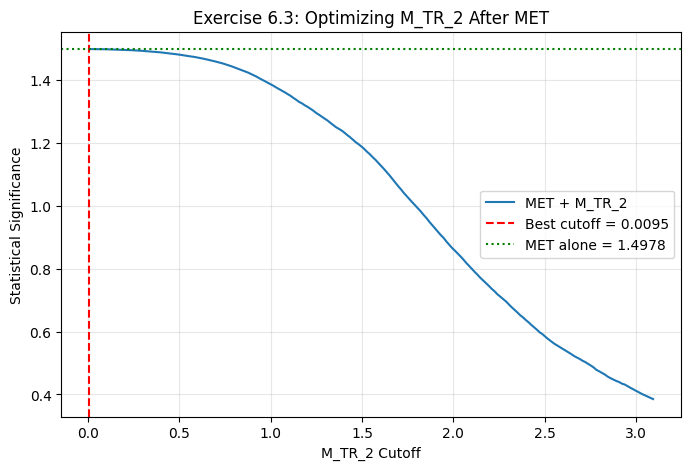

In [74]:
# Exercise 6.3: Re-optimize second cutoff after MET selection

import numpy as np
import matplotlib.pyplot as plt

# Scenario 1
NS = 10
NB = 100

# First cut
met_cut = 1.5471
first_cut = df["MET"].to_numpy() > met_cut

# Second variable
var = "M_TR_2"

# Test different cutoff values
cutoffs = np.linspace(
    df[var].min(),
    df[var].quantile(0.99),
    200
)

significances = []

for cutoff in cutoffs:

    # Apply both cuts
    selected = first_cut & (df[var].to_numpy() > cutoff)

    # Signal and background efficiencies
    eps_S = np.mean(
        selected[df["signal"].to_numpy() == 1]
    )

    eps_B = np.mean(
        selected[df["signal"].to_numpy() == 0]
    )

    # Expected selected events
    S = eps_S * NS
    B = eps_B * NB

    # Significance
    sig = S / np.sqrt(S + B) if S + B > 0 else 0

    significances.append(sig)

significances = np.array(significances)

# Find best cutoff
best_index = np.argmax(significances)
best_cutoff = cutoffs[best_index]
best_significance = significances[best_index]

print(f"Best M_TR_2 cutoff after MET: {best_cutoff:.4f}")
print(f"Maximum significance: {best_significance:.4f}")

# Plot
plt.figure(figsize=(8, 5))

plt.plot(cutoffs, significances, label="MET + M_TR_2")
plt.axvline(
    best_cutoff,
    color="red",
    linestyle="--",
    label=f"Best cutoff = {best_cutoff:.4f}"
)

plt.axhline(
    1.4978,
    color="green",
    linestyle=":",
    label="MET alone = 1.4978"
)

plt.xlabel("M_TR_2 Cutoff")
plt.ylabel("Statistical Significance")
plt.title("Exercise 6.3: Optimizing M_TR_2 After MET")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [75]:
# Exercise 6.3: Compare different cut orders

import numpy as np
import pandas as pd
from itertools import permutations

cuts = {
    "MET": 1.5471,
    "M_TR_2": 1.3174,
    "l_1_pT": 0.9339
}

# Scenario 1
NS, NB = 10, 100

signal = df["signal"].to_numpy() == 1
background = ~signal

results = []

# Test all 6 possible cut orders
for order in permutations(cuts.keys()):

    selected = np.ones(len(df), dtype=bool)

    for step, var in enumerate(order, start=1):

        selected &= df[var].to_numpy() > cuts[var]

        eps_S = selected[signal].mean()
        eps_B = selected[background].mean()

        S = NS * eps_S
        B = NB * eps_B

        significance = (
            S / np.sqrt(S + B)
            if S + B > 0 else 0
        )

        results.append({
            "Cut Order": " → ".join(order),
            "Step": step,
            "Applied Cut": var,
            "Signal Efficiency": eps_S,
            "Background Efficiency": eps_B,
            "Significance": significance
        })

order_df = pd.DataFrame(results)

display(order_df.round(4))

# Compare final significance across all orders
print("Final significance for each cut order:")

display(
    order_df[order_df["Step"] == 3][
        ["Cut Order", "Significance"]
    ].round(4)
)

,Cut Order,Step,Applied Cut,Signal Efficiency,Background Efficiency,Significance
0,MET → M_TR_2 → l_1_pT,1,MET,0.3228,0.0142,1.4978
1,MET → M_TR_2 → l_1_pT,2,M_TR_2,0.2330,0.0105,1.2677
2,MET → M_TR_2 → l_1_pT,3,l_1_pT,0.1909,0.0074,1.1726
3,MET → l_1_pT → M_TR_2,1,MET,0.3228,0.0142,1.4978
4,MET → l_1_pT → M_TR_2,2,l_1_pT,0.2286,0.0075,1.3112
5,MET → l_1_pT → M_TR_2,3,M_TR_2,0.1909,0.0074,1.1726
6,M_TR_2 → MET → l_1_pT,1,M_TR_2,0.3845,0.0531,1.2707
7,M_TR_2 → MET → l_1_pT,2,MET,0.2330,0.0105,1.2677
8,M_TR_2 → MET → l_1_pT,3,l_1_pT,0.1909,0.0074,1.1726
9,M_TR_2 → l_1_pT → MET,1,M_TR_2,0.3845,0.0531,1.2707


Final significance for each cut order:


,Cut Order,Significance
2,MET → M_TR_2 → l_1_pT,1.1726
5,MET → l_1_pT → M_TR_2,1.1726
8,M_TR_2 → MET → l_1_pT,1.1726
11,M_TR_2 → l_1_pT → MET,1.1726
14,l_1_pT → MET → M_TR_2,1.1726
17,l_1_pT → M_TR_2 → MET,1.1726


In [ ]:
#The correlation analysis showed that MET and M_TR_2 were strongly positively correlated (r = 0.7197), while M_TR_2 and l_1_pT were also strongly correlated (r = 0.7228). After applying the MET cutoff, re-optimizing M_TR_2 produced an optimal cutoff of approximately 0.0095, with a maximum significance of 1.4978. This was equal to the significance obtained using MET alone, suggesting that M_TR_2 did not provide additional improvement after the MET selection.

## Exercise 7: ROC Curves

### Exercise 7.1
For the top 3 observables you identified earlier, create one figure overlaying the Receiver Operating Characteristic (ROC) curves for the 3 observables. Compute the area under the curves and report it in the legend of the figure.

### Exercise 7.2
Write a function that you can use to quickly create the figure in Exercise 7.1 with other observables and different conditions. Note that you will likely revise this function as you do the remainder of the lab.

### Exercise 7.3
Use the function from Exercise 7.2 to compare the ROC curves for the successive selections in Exercise 6. Specifically, plot the ROC curve after each selection.

### Exercise 7.4
Use your function and appropriate example to demonstrate the effect (if any) of changing order of the successive selections.



In [78]:
%pip install scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 35.3 MB/s  0:00:00.4 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.3/30.3 MB 34.6 MB/s  0:00:00a 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [scikit-learn]0m 3/4 [scikit-learn]
Note: you may need to restart the kernel to use updated packages.


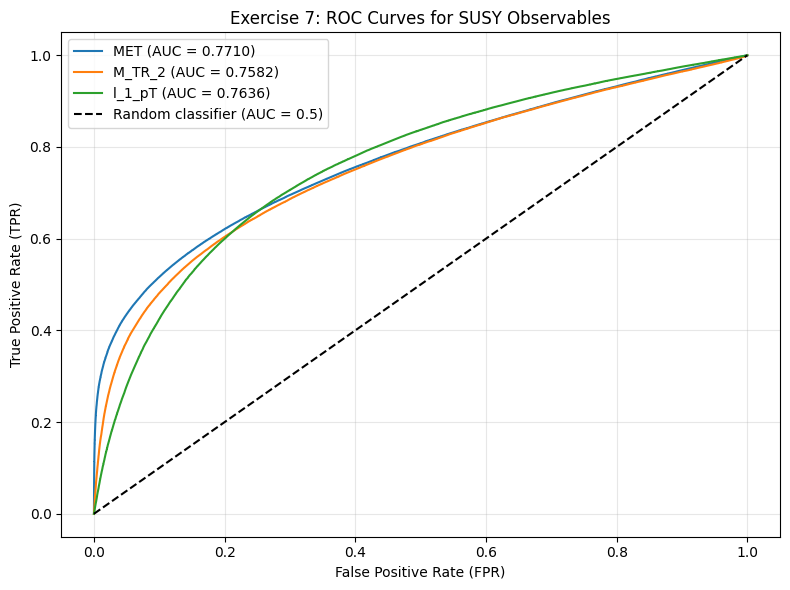

,Variable,AUC
0,MET,0.7710
2,l_1_pT,0.7636
1,M_TR_2,0.7582


In [81]:
# Exercise 7: ROC Curves

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

# True labels
y_true = df["signal"]

# Three observables from Exercise 6
selected_vars = ["MET", "M_TR_2", "l_1_pT"]

plt.figure(figsize=(8, 6))

auc_results = []

for var in selected_vars:

    # Observable values act as classification scores
    scores = df[var]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_true, scores)

    # Calculate AUC
    auc_value = roc_auc_score(y_true, scores)

    # Plot
    plt.plot(
        fpr, tpr,
        label=f"{var} (AUC = {auc_value:.4f})"
    )

    auc_results.append({
        "Variable": var,
        "AUC": auc_value
    })

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    "k--",
    label="Random classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("Exercise 7: ROC Curves for SUSY Observables")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Display AUC values
auc_df = pd.DataFrame(auc_results)

display(auc_df.sort_values("AUC", ascending=False).round(4))

In [83]:
# Exercise 7.2: Reusable ROC plotting function

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

def plot_roc(data, variables, title="ROC Curves", selections=None):

    plt.figure(figsize=(8, 6))

    # Optional selection conditions
    if selections is not None:
        for var, cutoff in selections.items():
            data = data[data[var] > cutoff]

    for var in variables:

        y_true = data["signal"]
        scores = data[var]

        # Calculate ROC curve and AUC
        fpr, tpr, thresholds = roc_curve(y_true, scores)
        auc_value = roc_auc_score(y_true, scores)

        plt.plot(
            fpr, tpr,
            label=f"{var} (AUC = {auc_value:.4f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        "k--", label="Random classifier"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

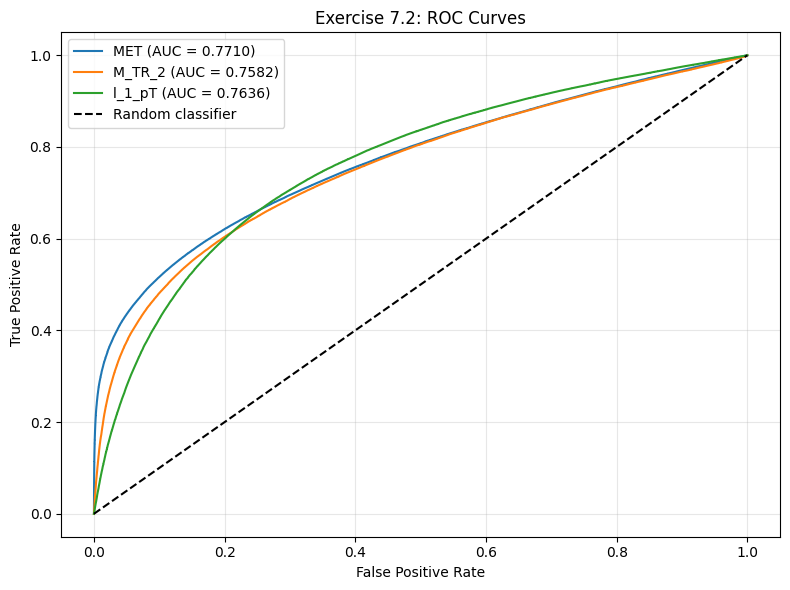

In [84]:
# Test function using the three observables from Exercise 7.1

plot_roc(
    df,
    ["MET", "M_TR_2", "l_1_pT"],
    title="Exercise 7.2: ROC Curves"
)

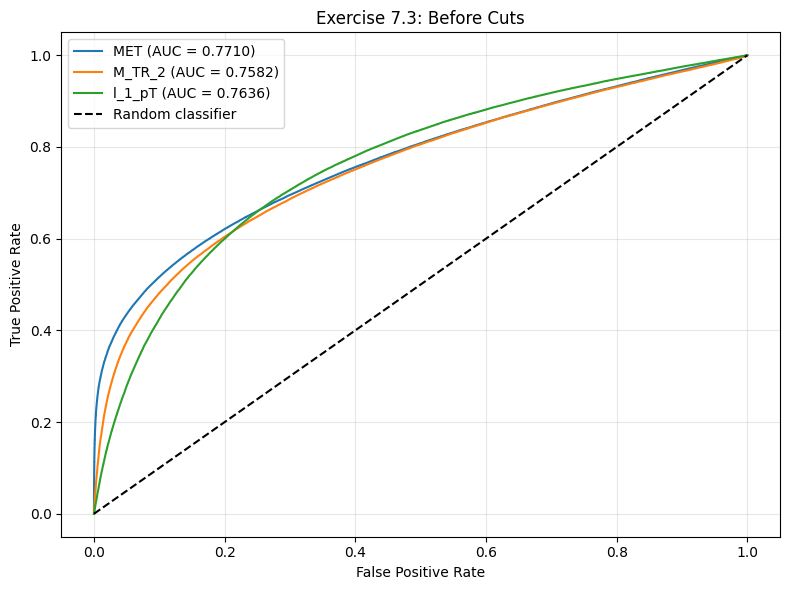

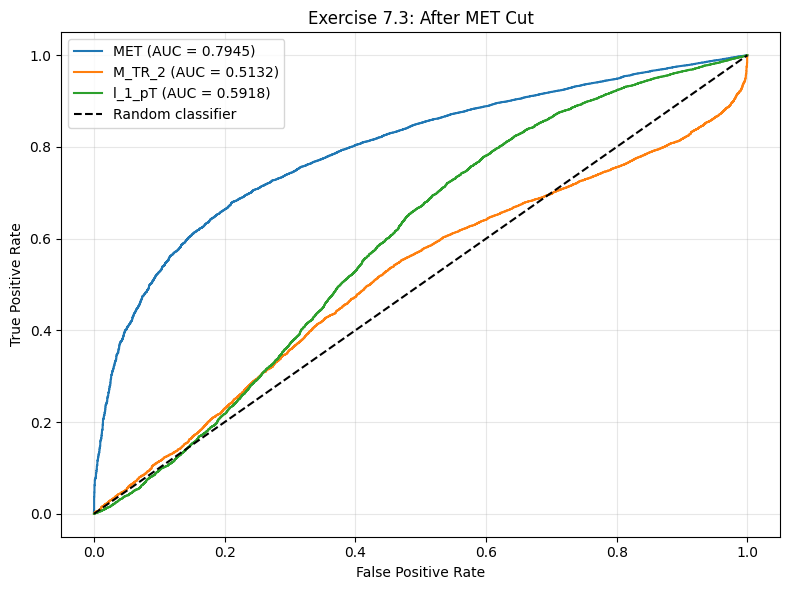

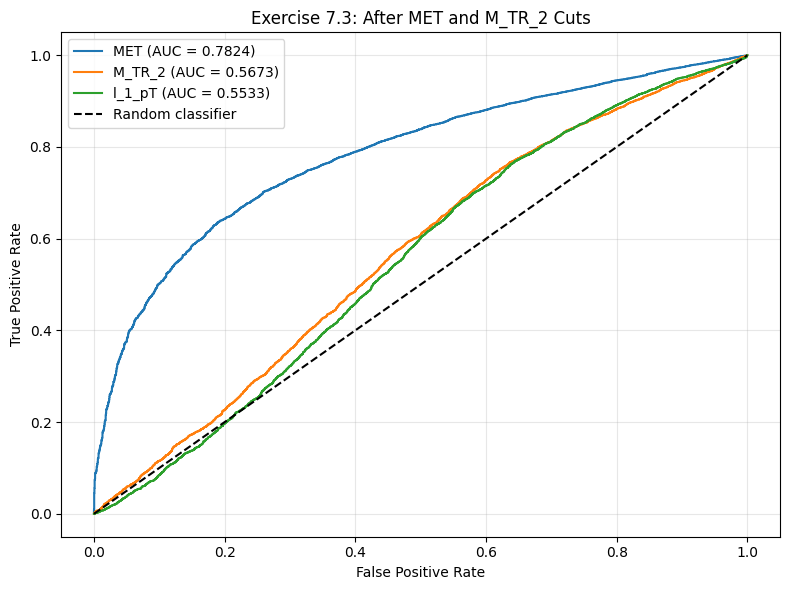

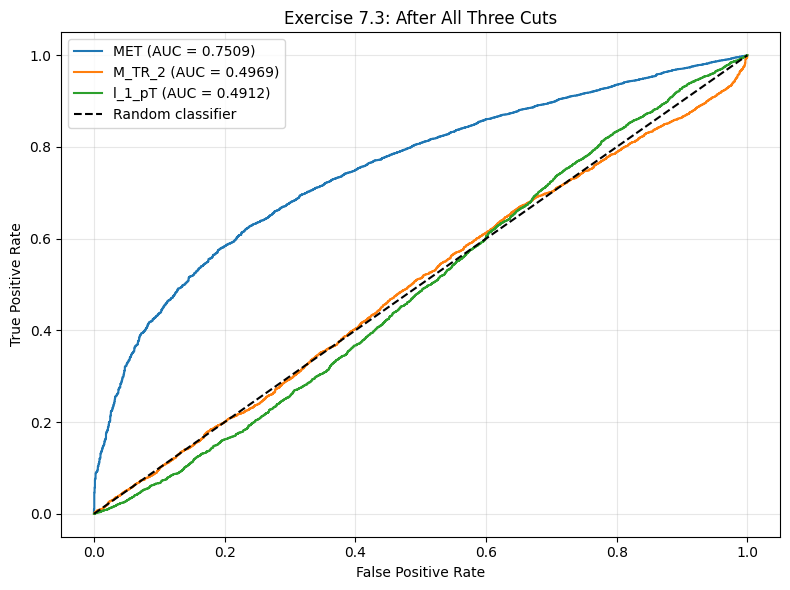

In [85]:
# Exercise 7.3: ROC curves after successive selections

cuts = {
    "MET": 1.5471,
    "M_TR_2": 1.3174,
    "l_1_pT": 0.9339
}

variables = ["MET", "M_TR_2", "l_1_pT"]

# Before any cuts
plot_roc(
    df,
    variables,
    title="Exercise 7.3: Before Cuts"
)

# After first cut
plot_roc(
    df,
    variables,
    title="Exercise 7.3: After MET Cut",
    selections={"MET": 1.5471}
)

# After first and second cuts
plot_roc(
    df,
    variables,
    title="Exercise 7.3: After MET and M_TR_2 Cuts",
    selections={
        "MET": 1.5471,
        "M_TR_2": 1.3174
    }
)

# After all three cuts
plot_roc(
    df,
    variables,
    title="Exercise 7.3: After All Three Cuts",
    selections=cuts
)

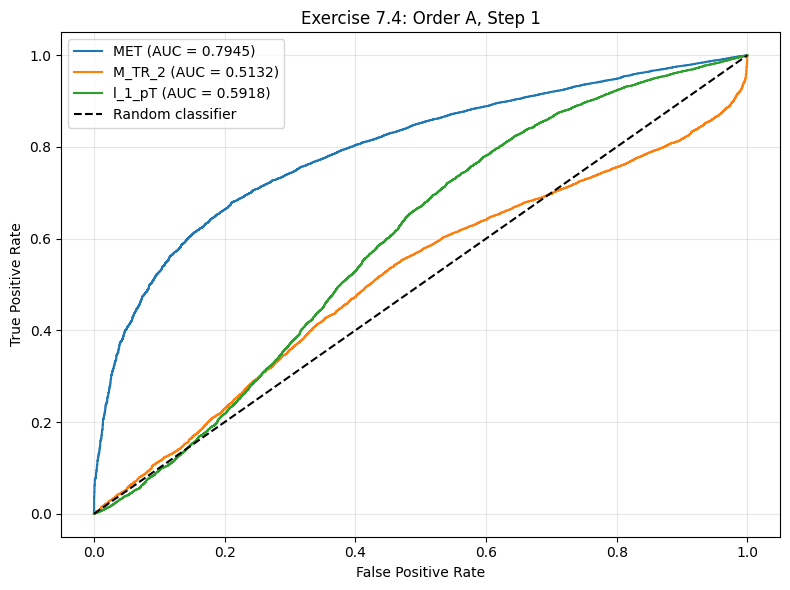

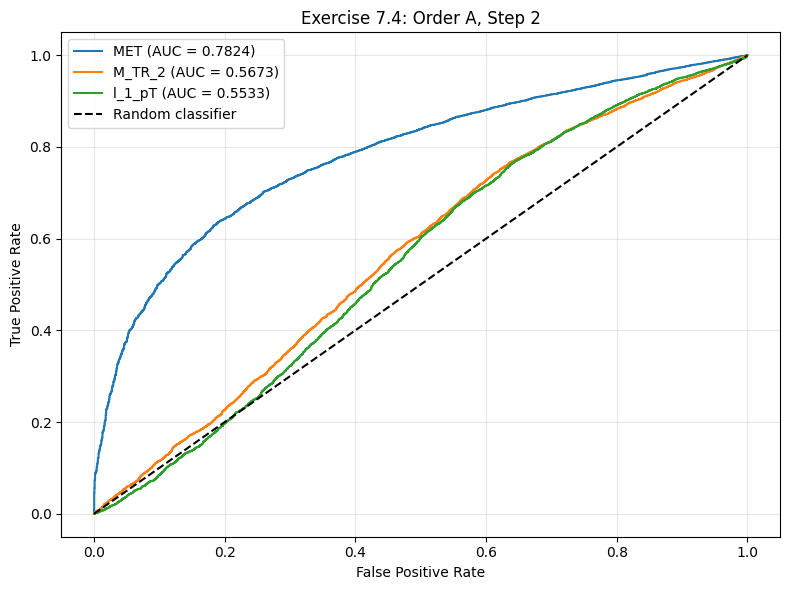

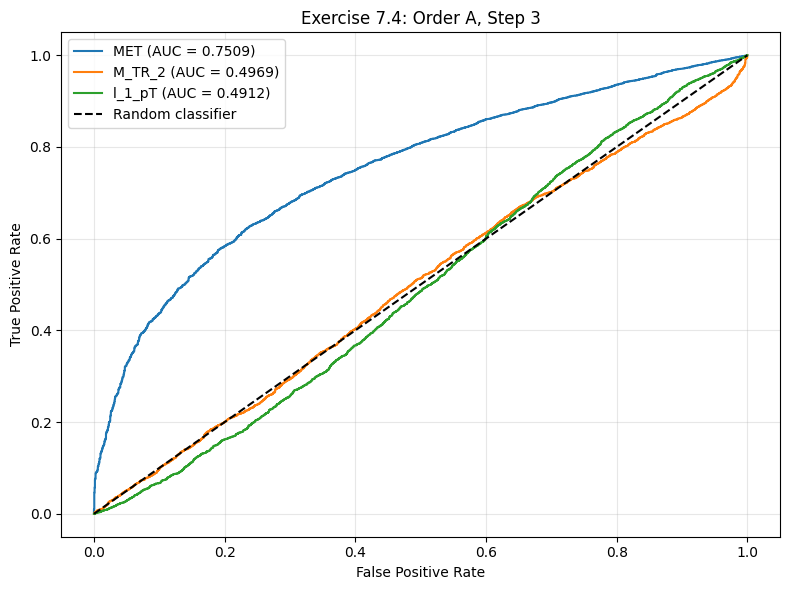

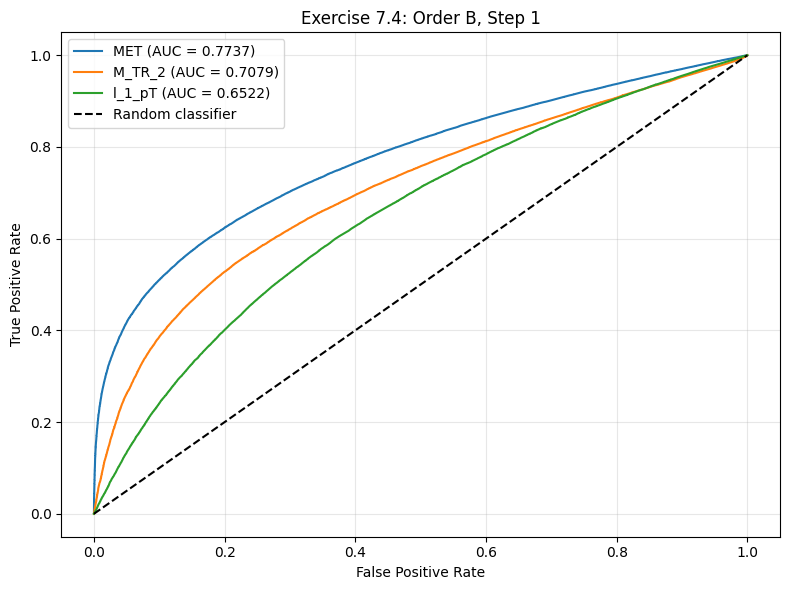

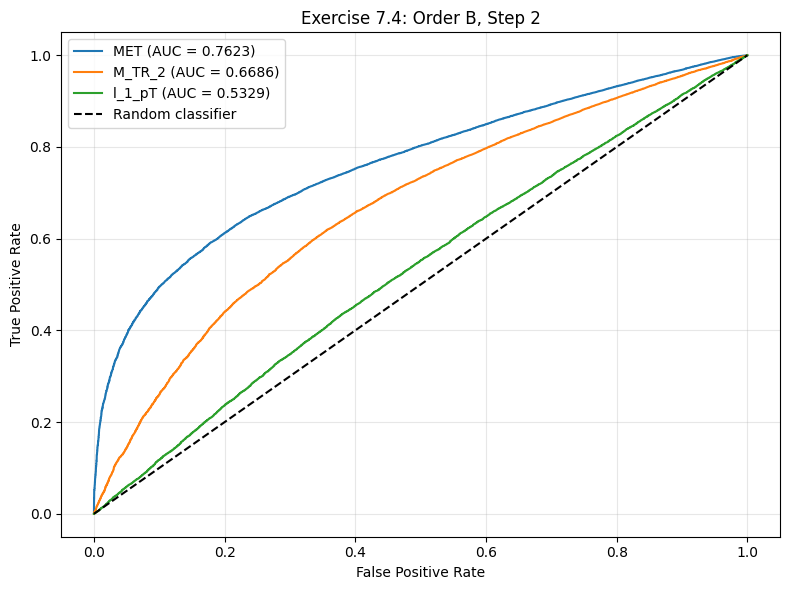

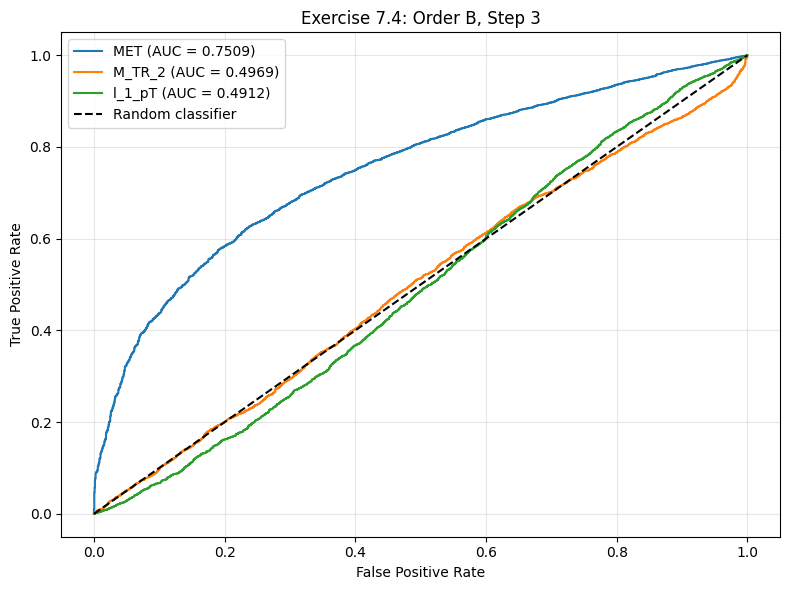

In [86]:
# Exercise 7.4: Effect of changing cut order

variables = ["MET", "M_TR_2", "l_1_pT"]

orders = {
    "Order A": [
        ("MET", 1.5471),
        ("M_TR_2", 1.3174),
        ("l_1_pT", 0.9339)
    ],
    "Order B": [
        ("l_1_pT", 0.9339),
        ("M_TR_2", 1.3174),
        ("MET", 1.5471)
    ]
}

for order_name, order in orders.items():

    selections = {}

    for step, (var, cutoff) in enumerate(order, start=1):

        selections[var] = cutoff

        plot_roc(
            df,
            variables,
            title=f"Exercise 7.4: {order_name}, Step {step}",
            selections=selections
        )

## Exercise 8: Linear Discriminant

This is Fisher's linear discriminant, which the machine-learning lectures cover.

### Exercise 8.1

Using numpy, compute the between-class $\bf{S}_B$ and within-class $\bf{S}_W$ covariance matrices defined as:

$$
\bf{S}_B = (\bf{m_2}-\bf{m_1})(\bf{m_2}-\bf{m_1})^T \\
$$
$$
\bf{S}_W = \sum_{i=1,2} \sum_{n=1}^{l_i} (\bf{x}_n^i - \bf{m}_i) (\bf{x}_n^i - \bf{m}_i)^T
$$

where $\bf{m_i}$ are the vectors containing the means for category 1 and 2, here defined as signal and background. Here $\bf{x}_n^i$ is the vector containing the observables for the $n$th example event in category $i$.

### Exercise 8.2

Compute the linear coefficients $\bf{w} = \bf{S_W}^{-1}(\bf{m_2}-\bf{m_1})$. Compare the histogram of the distribution of $F_n^i=\bf{w}^T\bf{x}_n^i$ for the two categories.

### Exercise 8.3

Draw the ROC curve for $F_n$. 

### Exercise 8.4

What is the maximal significance you can obtain in the scenarios in exercise 5? 

In [87]:
# Exercise 8.1: Fisher's Linear Discriminant matrices

import numpy as np
import pandas as pd

# All 18 observables
features = VarNames[1:]

# Separate signal and background
X_signal = df_sig[features].to_numpy()
X_background = df_bkg[features].to_numpy()

# Mean vectors
m1 = np.mean(X_signal, axis=0)
m2 = np.mean(X_background, axis=0)

# Between-class scatter matrix
mean_diff = m2 - m1
SB = np.outer(mean_diff, mean_diff)

# Center the data
X_signal_centered = X_signal - m1
X_background_centered = X_background - m2

# Within-class scatter matrix
SW = (
    X_signal_centered.T @ X_signal_centered
    + X_background_centered.T @ X_background_centered
)

print("Between-class matrix SB:")
display(pd.DataFrame(SB, index=features, columns=features).round(4))

print("Within-class matrix SW:")
display(pd.DataFrame(SW, index=features, columns=features).round(4))

print("SB shape:", SB.shape)
print("SW shape:", SW.shape)

Between-class matrix SB:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,0.2880,0.0005,0.0005,0.1381,0.0015,0.0004,0.4135,-0.0006,0.2711,0.0855,0.1823,0.2666,0.0553,0.0738,0.1742,0.1841,0.0154,0.0566
l_1_eta,0.0005,0.0000,0.0000,0.0002,0.0000,0.0000,0.0007,-0.0000,0.0004,0.0001,0.0003,0.0004,0.0001,0.0001,0.0003,0.0003,0.0000,0.0001
l_1_phi,0.0005,0.0000,0.0000,0.0002,0.0000,0.0000,0.0007,-0.0000,0.0004,0.0001,0.0003,0.0004,0.0001,0.0001,0.0003,0.0003,0.0000,0.0001
l_2_pT,0.1381,0.0002,0.0002,0.0663,0.0007,0.0002,0.1984,-0.0003,0.1301,0.0410,0.0875,0.1279,0.0265,0.0354,0.0836,0.0883,0.0074,0.0272
l_2_eta,0.0015,0.0000,0.0000,0.0007,0.0000,0.0000,0.0022,-0.0000,0.0015,0.0005,0.0010,0.0014,0.0003,0.0004,0.0009,0.0010,0.0001,0.0003
l_2_phi,0.0004,0.0000,0.0000,0.0002,0.0000,0.0000,0.0005,-0.0000,0.0003,0.0001,0.0002,0.0003,0.0001,0.0001,0.0002,0.0002,0.0000,0.0001
MET,0.4135,0.0007,0.0007,0.1984,0.0022,0.0005,0.5936,-0.0009,0.3893,0.1227,0.2618,0.3827,0.0794,0.1059,0.2502,0.2644,0.0221,0.0813
MET_phi,-0.0006,-0.0000,-0.0000,-0.0003,-0.0000,-0.0000,-0.0009,0.0000,-0.0006,-0.0002,-0.0004,-0.0006,-0.0001,-0.0002,-0.0004,-0.0004,-0.0000,-0.0001
MET_rel,0.2711,0.0004,0.0004,0.1301,0.0015,0.0003,0.3893,-0.0006,0.2553,0.0805,0.1717,0.2510,0.0521,0.0695,0.1641,0.1734,0.0145,0.0533
axial_MET,0.0855,0.0001,0.0001,0.0410,0.0005,0.0001,0.1227,-0.0002,0.0805,0.0254,0.0541,0.0791,0.0164,0.0219,0.0517,0.0546,0.0046,0.0168


Within-class matrix SW:


,l_1_pT,l_1_eta,l_1_phi,l_2_pT,l_2_eta,l_2_phi,MET,MET_phi,MET_rel,axial_MET,M_R,M_TR_2,R,MT2,S_R,M_Delta_R,dPhi_r_b,cos_theta_r1
l_1_pT,197992.3142,-255.3066,-19.7201,135369.1269,-365.6708,323.2210,62890.4849,-389.3275,15103.4849,-15475.8396,159581.4884,110521.3976,-36718.8498,-15358.6322,149663.0616,26013.4287,-25386.9596,4051.8756
l_1_eta,-255.3066,502149.6230,-428.9070,-108.7830,204155.7338,-521.0766,-1155.2830,-294.3576,-738.9243,-571.3530,-312.9839,-387.1933,139.7050,198.9643,-336.4749,-530.1589,-373.2121,149.6129
l_1_phi,-19.7201,-428.9070,501985.5840,628.6395,125.0467,-133404.8960,299.8630,-92401.6755,298.4639,-953.5664,494.7892,380.6748,89.6491,515.2765,696.7688,413.5132,494.0474,118.1375
l_2_pT,135369.1269,-108.7830,628.6395,204517.4547,-379.5376,56.1397,15102.8953,-742.9710,-16413.9894,20575.1196,151858.4668,65595.9954,-52970.0971,-38836.8331,150592.9868,-8106.9238,-2834.7812,-17327.4784
l_2_eta,-365.6708,204155.7338,125.0467,-379.5376,503130.1990,220.5505,-83.7780,-160.8016,362.0672,-434.9877,-424.9317,-167.5986,123.5690,650.4424,-455.0146,212.9348,-163.6672,110.5600
l_2_phi,323.2210,-521.0766,-133404.8960,56.1397,220.5505,501898.1004,-217.2387,-17717.0157,680.7250,-913.7381,351.1819,212.3923,266.8412,1117.9285,425.7199,634.2396,-123.0356,9.5831
MET,62890.4849,-1155.2830,299.8630,15102.8953,-83.7780,-217.2387,307430.1902,-1282.5940,224914.0714,61744.9175,39762.7766,135086.6792,84095.4273,64241.7739,51715.1882,124755.3374,70094.9680,26452.9776
MET_phi,-389.3275,-294.3576,-92401.6755,-742.9710,-160.8016,-17717.0157,-1282.5940,501655.3981,-2373.1877,-197.4403,-691.5358,-527.3469,-99.5826,62.1826,-805.5545,-234.3973,-850.3005,75.2430
MET_rel,15103.4849,-738.9243,298.4639,-16413.9894,362.0672,680.7250,224914.0714,-2373.1877,363552.9121,-69914.8510,531.0012,119840.3214,117945.3252,195765.2267,20791.9386,185851.2662,71418.9090,21040.0960
axial_MET,-15475.8396,-571.3530,-953.5664,20575.1196,-434.9877,-913.7381,61744.9175,-197.4403,-69914.8510,499537.1937,1849.6798,-102328.8973,-92488.1249,-233217.1809,-27110.8960,-123320.0907,-13123.9563,-28953.7003


SB shape: (18, 18)
SW shape: (18, 18)


,Observable,Coefficient
0,l_1_pT,-2.270000e-06
1,l_1_eta,-1.000000e-08
2,l_1_phi,-0.000000e+00
3,l_2_pT,-1.000000e-06
4,l_2_eta,-0.000000e+00
5,l_2_phi,-0.000000e+00
6,MET,-1.650000e-06
7,MET_phi,-0.000000e+00
8,MET_rel,-1.400000e-07
9,axial_MET,-2.600000e-07


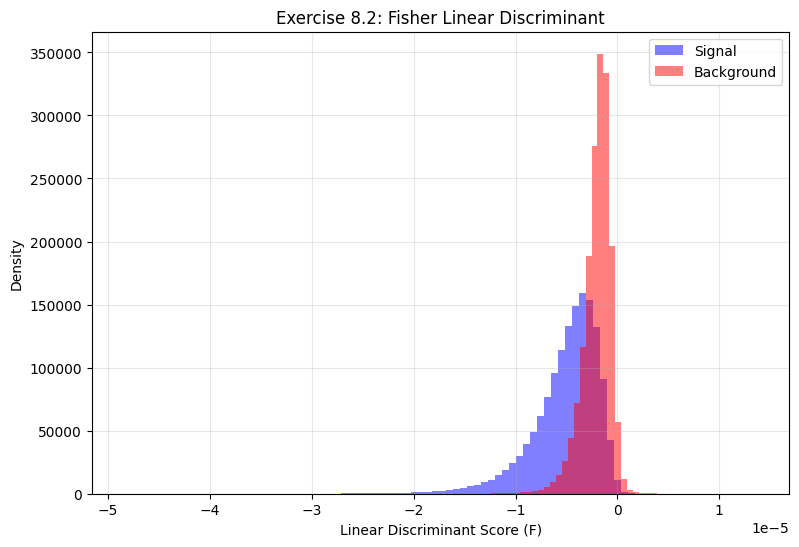

In [88]:
# Exercise 8.2: Linear discriminant coefficients

import matplotlib.pyplot as plt

# Calculate w
# np.linalg.solve is numerically preferable to explicit inversion
w = np.linalg.solve(SW, mean_diff)

# Display coefficients
coefficients = pd.DataFrame({
    "Observable": features,
    "Coefficient": w
})

display(coefficients.round(8))

# Compute linear discriminant scores
F_signal = X_signal @ w
F_background = X_background @ w

# Plot histograms
plt.figure(figsize=(9, 6))

plt.hist(
    F_signal,
    bins=80,
    density=True,
    alpha=0.5,
    label="Signal",
    color="blue"
)

plt.hist(
    F_background,
    bins=80,
    density=True,
    alpha=0.5,
    label="Background",
    color="red"
)

plt.xlabel("Linear Discriminant Score (F)")
plt.ylabel("Density")
plt.title("Exercise 8.2: Fisher Linear Discriminant")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

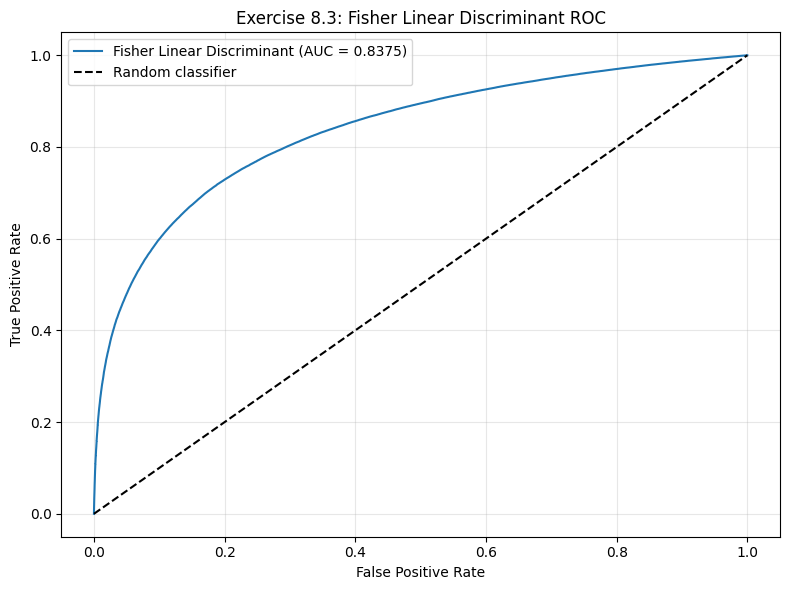

Fisher AUC: 0.8375


In [89]:
# Exercise 8.3: ROC curve for Fisher's Linear Discriminant

from sklearn.metrics import roc_curve, roc_auc_score

# Combine signal and background scores
F_all = df[features].to_numpy() @ w

# True labels
y_true = df["signal"].to_numpy()

# Reverse score direction so higher values favor signal
signal_scores = -F_all

# ROC curve
fpr, tpr, thresholds = roc_curve(y_true, signal_scores)

# AUC
auc_fisher = roc_auc_score(y_true, signal_scores)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Fisher Linear Discriminant (AUC = {auc_fisher:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Exercise 8.3: Fisher Linear Discriminant ROC")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Fisher AUC: {auc_fisher:.4f}")

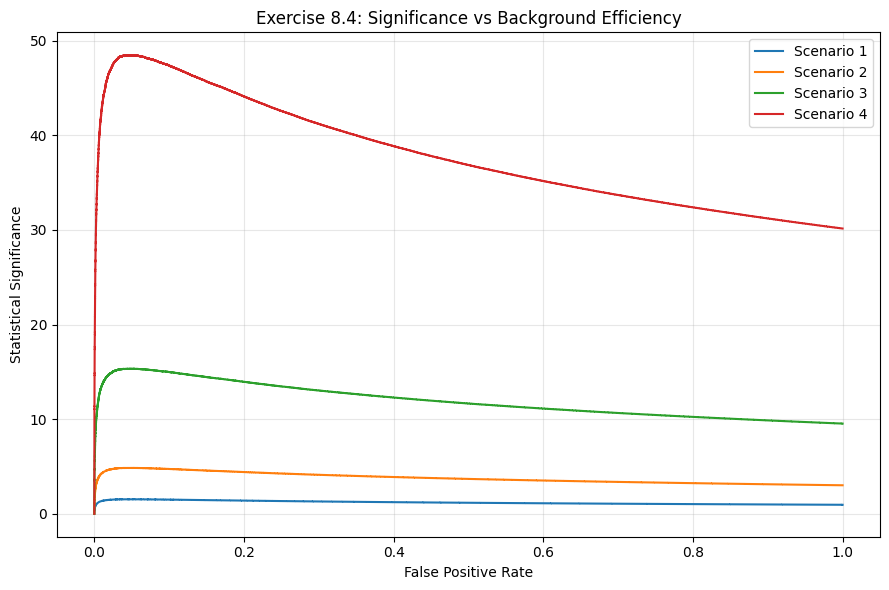

,Scenario,NS,NB,Best Threshold,Max Significance
0,1,10,100,0.0,1.5326
1,2,100,1000,0.0,4.8464
2,3,1000,10000,0.0,15.3257
3,4,10000,100000,0.0,48.4641


In [90]:
# Exercise 8.4: Maximum statistical significance

scenarios = [
    (10, 100),
    (100, 1000),
    (1000, 10000),
    (10000, 100000)
]

results = []

plt.figure(figsize=(9, 6))

for scenario_num, (NS, NB) in enumerate(scenarios, start=1):

    # Expected events after selection
    S = tpr * NS
    B = fpr * NB

    # Significance
    significance = np.divide(
        S,
        np.sqrt(S + B),
        out=np.zeros_like(S),
        where=(S + B) > 0
    )

    # Find maximum significance
    best_idx = np.argmax(significance)

    results.append({
        "Scenario": scenario_num,
        "NS": NS,
        "NB": NB,
        "Best Threshold": thresholds[best_idx],
        "Max Significance": significance[best_idx]
    })

    plt.plot(
        fpr,
        significance,
        label=f"Scenario {scenario_num}"
    )

plt.xlabel("False Positive Rate")
plt.ylabel("Statistical Significance")
plt.title("Exercise 8.4: Significance vs Background Efficiency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Results table
fisher_results = pd.DataFrame(results)

display(fisher_results.round(4))